# Data quality analysis
This notebook does an analysis of the data quality of each dataset, and goes through measures to handle data quality issues such as duplicates, missing values, wrong formats etc.  

The notebook follows a structure where each dataset is analysed by first doing a qualitiative assesment, and then a quantitative assessment by checking the actual contents of data.

**AI notice:** The code in this notebook is created with assistance by the GitHub Copilot AI. All generated code has been manually validated and/or corrected by the researcher to make sure it serves the intended purpose. The actual analysis is done by the researcher themselves.

### General focus and aim
- Focus on these data:
    - Actual, departed trains (thus exclude cancelled trains)
    - Time period of analysis, limited by findings of data exploration: 01-08-2025 to 16-09-2026
- Aim of the general analysis which should be conducted for the study:
    - Short analysis of departure delays compared to all departed trains
    - More thorough analysis of departure delays, isolated
        - Delay reason codes (Årsakskoder)
        - Also try: Which sub-processes stands for most delay?

### Quantitative analysis content:
The data quality analysis should assess these, quantitative aspects for each dataset:
- Data types/formats
    - For each relevant, chosen columns ^^
- Expected dates for analysis period
    - All dates covered?
    - Any gaps in the middle of the study period?
- Row level contents
    - Blank rows?
    - Duplicate rows?
    - Rows w/o train ID (Tognummer)?
    - Planned departures w/o actual departure times?
    - Actual departures w/o planned departure?
- Column level contents - missing values
    - For each relevant, chosen column ^^
    - (Distignuish between if missing values are ok or not, e.g. punctual departures have no delay code)
- Grain uniqueness and duplicates
    - LoggTogID
- Scope of edge cases
    - Overnight departures
    - Outliers
        - Very large delays
        - Very early departures (deviation from planned)

## Import of programming packages

In [140]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## bronze_tp_operating_train_routes_ALB

### Qualitative aspects

**Data collection procedure:** 
- A -- Bronze dataset apparently based on OTR data (Operating Train Routes), provided by Vygruppen (according to a medallion dataset architecture). Should be automatically generated data, but formatted after staging area. Only filtered to CargoNets trains at Alnabru. Contains *all* of CargoNet registrered train arrivals and departures at Alnabru.
- B -- Data pulled from electronic systems, should have no manual data inputs.

**Comment:**
- A & B -- No manual data means less vulnerable to human typos etc.
- As these data contains a lot of automatically, "real" electronic input data, the dataset might be able to filter out all cancelled trains (which shouldn't be included in the analysis)
- This dataset should theoretically have the "facts" for which trains departed, and which ones were cancelled

**Relevant columns to use:**
- `train_id`
- `train_date`
- `cancelled`
- `scheduled_departure_time`
- `actual_departure_time`
- `actual_arrival_time`
- `estimated_arrival_time`
- `just_passing_through`
- `departure_delay`
- `train_company`

### Quantitative aspects

#### Preparation

In [141]:
# Import
df_vy_alnabru_timings = pd.read_csv("../data/bronze_tp_operating_train_routes_ALB.csv", sep=";", encoding="utf-8-sig")


In [142]:
# Define the inclusive date interval
start_date = pd.Timestamp("2025-08-01")
end_date = pd.Timestamp("2026-09-16")

# Convert Avgangsdato in the dataframe to a usable format
df_vy_alnabru_timings["train_date"] = pd.to_datetime(
    df_vy_alnabru_timings["train_date"],
    format="%Y-%m-%d",
    errors="coerce"
)

# Filter the dataset based on time period
df_vy_timings_filtered = (
    df_vy_alnabru_timings[
        df_vy_alnabru_timings["train_date"].between(
            start_date,
            end_date,
            inclusive="both"
        )
    ]
    .copy()
    .reset_index(drop=True)
)

In [143]:
print("Number of rows:", len(df_vy_timings_filtered))
print(
    "Date range:",
    df_vy_timings_filtered["train_date"].min(),
    "to",
    df_vy_timings_filtered["train_date"].max()
)
print(df_vy_timings_filtered["train_date"].dtype)

Number of rows: 19952
Date range: 2025-08-01 00:00:00 to 2026-09-16 00:00:00
datetime64[us]


In [144]:
# Select the relevant columns for further analysis
relevant_columns = [
    "train_id",
    "train_date",
    "cancelled",
    "scheduled_departure_time",
    "actual_departure_time",
    "actual_arrival_time",
    "estimated_arrival_time",
    "just_passing_through",
    "departure_delay",
    "train_company"
]

df_vy_timings_filtered = (
    df_vy_timings_filtered[relevant_columns]
    .copy()
)

In [145]:
# Check filtering
print("Dimensions of filtered table:", df_vy_timings_filtered.shape)
df_vy_timings_filtered.columns.tolist()

Dimensions of filtered table: (19952, 10)


['train_id',
 'train_date',
 'cancelled',
 'scheduled_departure_time',
 'actual_departure_time',
 'actual_arrival_time',
 'estimated_arrival_time',
 'just_passing_through',
 'departure_delay',
 'train_company']

In [146]:
# Constructing the LoggTogID column
df_vy_timings_filtered["LoggTogID"] = (
    df_vy_timings_filtered["train_date"].dt.strftime("%d-%m-%Y")
    + "_"
    + df_vy_timings_filtered["train_id"].astype(str)
)

df_vy_timings_filtered[["train_id", "train_date", "LoggTogID"]].head()

,train_id,train_date,LoggTogID
0,21524,2026-09-16,16-09-2026_21524
1,21525,2026-09-16,16-09-2026_21525
2,21526,2026-09-16,16-09-2026_21526
3,21527,2026-09-16,16-09-2026_21527
4,21571,2026-09-16,16-09-2026_21571


*Comment:* Analysis should not use cancelled trains or trains just passing through, and should only be CargoNet trains

In [147]:
# Checking if it only contains CargoNet trains
df_vy_timings_filtered["train_company"].value_counts(dropna=False)

train_company
CN    19952
Name: count, dtype: int64

In [148]:
# Checking values of cancelled
df_vy_timings_filtered["cancelled"].value_counts(dropna=False)

cancelled
N    16644
Y     2445
P      863
Name: count, dtype: int64

In [149]:
# Checking values of just_passing_through
df_vy_timings_filtered["just_passing_through"].value_counts(dropna=False)

just_passing_through
False    12127
True      7825
Name: count, dtype: int64

In [ ]:
# Collect cancelled trains in a separate table (for later use)
df_vy_cancelled_trains = df_vy_timings_filtered[
    df_vy_timings_filtered["cancelled"] == "Y"
].copy()

# Filter out cancelled trains and just_passing_through trains
df_vy_timings_filtered = df_vy_timings_filtered[
    (df_vy_timings_filtered["cancelled"] == "N") &
    (df_vy_timings_filtered["just_passing_through"] == False)
].copy()

# Identify rows that contain arrival information but no departure information
has_arrival_time = (
    df_vy_timings_filtered["actual_arrival_time"].notna() |
    df_vy_timings_filtered["estimated_arrival_time"].notna()
)
has_departure_time = (
    df_vy_timings_filtered["scheduled_departure_time"].notna() |
    df_vy_timings_filtered["actual_departure_time"].notna()
)

arrival_only_trains = df_vy_timings_filtered[
    has_arrival_time & ~has_departure_time
].copy()

print("Arrival-only trains before removal:", len(arrival_only_trains))

# Check whether rows missing departure times have arrival times
missing_departure_rows = df_vy_timings_filtered[~has_departure_time].copy()
missing_departure_summary = pd.Series({
    "Rows missing both departure times": len(missing_departure_rows),
    "Missing departure rows with arrival time": (
        has_arrival_time[~has_departure_time].sum()
    ),
    "Missing departure rows without arrival time": (
        (~has_arrival_time[~has_departure_time]).sum()
    )
})


missing_departure_with_arrival = missing_departure_rows[
    has_arrival_time[~has_departure_time]
].copy()

missing_departure_without_arrival = missing_departure_rows[
    ~has_arrival_time[~has_departure_time]
].copy()

# Keep rows relevant to departure analysis; retain rows without timestamps
# for the separate missing-value assessment below.
df_vy_timings_filtered = df_vy_timings_filtered[
    ~(
        df_vy_timings_filtered["actual_arrival_time"].notna() |
        df_vy_timings_filtered["estimated_arrival_time"].notna()
    ) |
    has_departure_time
].copy()

missing_departure_summary

Arrival-only trains before removal: 4597


Rows missing both departure times              4710
Missing departure rows with arrival time       4597
Missing departure rows without arrival time     113
dtype: int64

In [151]:
# Checking cancelled values after filtering
df_vy_timings_filtered["cancelled"].value_counts(dropna=False)

cancelled
N    4968
Name: count, dtype: int64

In [152]:
# Checking values of just_passing_through after filtering
df_vy_timings_filtered["just_passing_through"].value_counts(dropna=False)

just_passing_through
False    4968
Name: count, dtype: int64

In [153]:
# Double check filtering
print("Dimensions of filtered table:", df_vy_timings_filtered.shape)
df_vy_timings_filtered.columns.tolist()

Dimensions of filtered table: (4968, 11)


['train_id',
 'train_date',
 'cancelled',
 'scheduled_departure_time',
 'actual_departure_time',
 'actual_arrival_time',
 'estimated_arrival_time',
 'just_passing_through',
 'departure_delay',
 'train_company',
 'LoggTogID']

#### Actual analysis

##### Expected dates for analysis period
- All dates covered?
- Any gaps in the middle of the study period?

In [154]:
# Define a function for use multiple times
def check_date_coverage(df, date_column, start_date, end_date, label):
    dates = pd.to_datetime(
        df[date_column],
        errors="coerce"
    ).dt.normalize()

    expected_dates = pd.date_range(
        start=start_date,
        end=end_date,
        freq="D"
    )

    observed_dates = pd.DatetimeIndex(
        dates.dropna().unique()
    ).sort_values()

    missing_dates = expected_dates.difference(observed_dates)

    daily_counts = (
        dates
        .value_counts()
        .reindex(expected_dates, fill_value=0)
        .sort_index()
        .rename("number_of_rows")
        .to_frame()
    )

    print(f"\n{label}")
    print("-" * len(label))
    print(f"Rows: {len(df)}")
    print(f"Rows with missing dates: {dates.isna().sum()}")
    print(f"Dates represented: {len(observed_dates)} of {len(expected_dates)}")
    print(f"Dates with no records: {len(missing_dates)}")

    if len(missing_dates) > 0:
        print("Missing dates:")
        print(missing_dates.strftime("%Y-%m-%d").tolist())
    else:
        print("All dates in the analysis period are represented.")

    return daily_counts, missing_dates

In [155]:
cancelled_daily_counts, cancelled_missing_dates = check_date_coverage(
    df=df_vy_cancelled_trains,
    date_column="train_date",
    start_date=start_date,
    end_date=end_date,
    label="Cancelled trains"
)

retained_daily_counts, retained_missing_dates = check_date_coverage(
    df=df_vy_timings_filtered,
    date_column="train_date",
    start_date=start_date,
    end_date=end_date,
    label="Retained trains"
)


Cancelled trains
----------------
Rows: 2445
Rows with missing dates: 0
Dates represented: 397 of 412
Dates with no records: 15
Missing dates:
['2025-12-10', '2025-12-17', '2025-12-18', '2026-01-13', '2026-01-14', '2026-01-15', '2026-01-22', '2026-02-10', '2026-02-24', '2026-03-10', '2026-03-18', '2026-05-19', '2026-06-18', '2026-09-03', '2026-09-08']

Retained trains
---------------
Rows: 4968
Rows with missing dates: 0
Dates represented: 406 of 412
Dates with no records: 6
Missing dates:
['2025-12-24', '2025-12-31', '2026-04-02', '2026-04-03', '2026-04-04', '2026-04-05']


*Comment:* After double-checking the internal CargoNet terminal logs, on the 4th and 5th of april all trains were cancelled. Thus, missing these dates in the 'departued'-table is ok

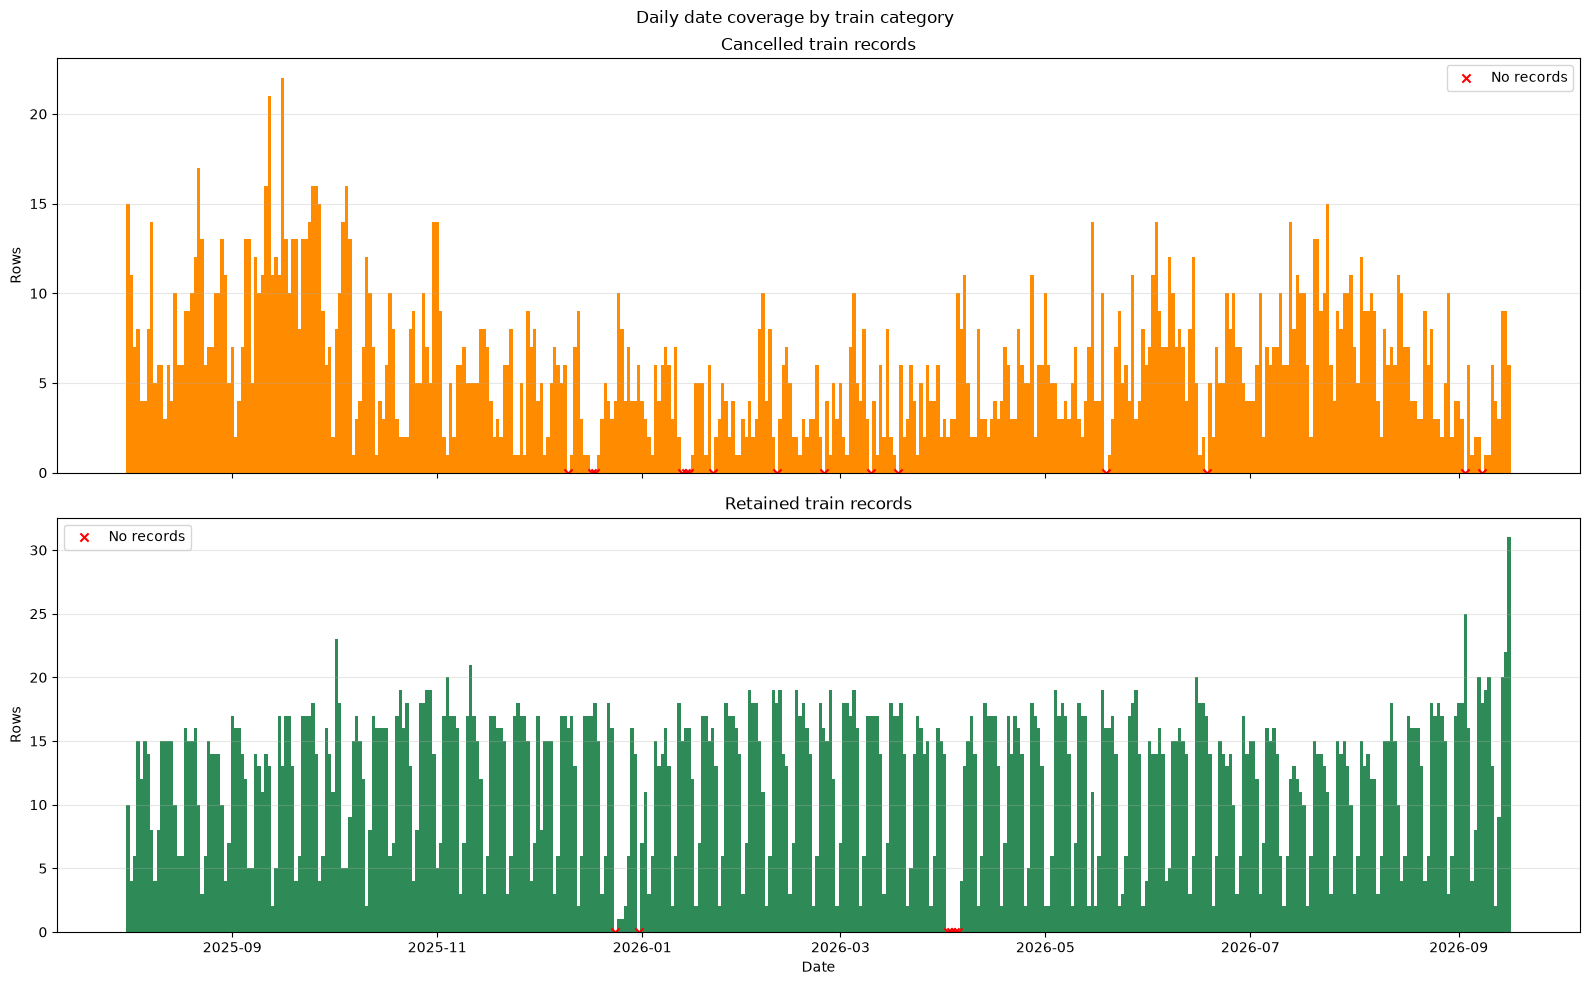

In [156]:
# Visualize the data

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(16, 10),
    sharex=True
)

datasets = [
    ("Cancelled train records", cancelled_daily_counts, "darkorange"),
    ("Retained train records", retained_daily_counts, "seagreen")
]

for ax, (label, daily_counts, color) in zip(axes, datasets):
    ax.bar(
        daily_counts.index,
        daily_counts["number_of_rows"],
        width=1.0,
        color=color
    )

    zero_dates = daily_counts.index[
        daily_counts["number_of_rows"] == 0
    ]

    ax.scatter(
        zero_dates,
        [0] * len(zero_dates),
        color="red",
        marker="x",
        s=35,
        label="No records"
    )

    ax.set_ylabel("Rows")
    ax.set_title(label)
    ax.grid(axis="y", alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Date")

plt.suptitle("Daily date coverage by train category")
plt.tight_layout()
plt.show()

##### Row level contents
- Duplicate rows?
- Blank rows?
- Rows w/o train ID (Tognummer)?
- Planned departures w/o actual departure times?
- Actual departures w/o planned departure?

- Arrival-only trains are identified separately using arrival timestamps and excluded from the departure analysis.

*Note: Checking only the departured trains, not the cancelled ones*

In [157]:
# Duplicate rows
duplicate_rows = df_vy_timings_filtered[
    df_vy_timings_filtered.duplicated(keep=False)
]

print(f"Number of duplicate rows: {len(duplicate_rows)}")
duplicate_rows

Number of duplicate rows: 0


,train_id,train_date,cancelled,scheduled_departure_time,actual_departure_time,actual_arrival_time,estimated_arrival_time,just_passing_through,departure_delay,train_company,LoggTogID


In [158]:
# Blank rows
blank_rows = df_vy_timings_filtered[
    df_vy_timings_filtered
    .replace(r"^\s*$", pd.NA, regex=True)
    .isna()
    .all(axis=1)
]

print(f"Number of blank rows: {len(blank_rows)}")

Number of blank rows: 0


In [159]:
# Comparing planned times vs. registered times
scheduled_missing = df_vy_timings_filtered["scheduled_departure_time"].isna()
actual_missing = df_vy_timings_filtered["actual_departure_time"].isna()

# Planned departure exists, but actual departure is missing
planned_without_actual = df_vy_timings_filtered[
    ~scheduled_missing & actual_missing
]

# Actual departure exists, but planned departure is missing
actual_without_planned = df_vy_timings_filtered[
    scheduled_missing & ~actual_missing
]

print(
    "Planned departures without actual departure:",
    len(planned_without_actual)
)

print(
    "Actual departures without planned departure:",
    len(actual_without_planned)
)

Planned departures without actual departure: 151
Actual departures without planned departure: 1


In [160]:
planned_without_actual[
    [
        "LoggTogID",
        "train_id",
        "train_date",
        "scheduled_departure_time",
        "actual_departure_time"
    ]
]

,LoggTogID,train_id,train_date,scheduled_departure_time,actual_departure_time
20,16-09-2026_41900,41900,2026-09-16,2026-09-16T18:26:00.000Z,NaN
22,16-09-2026_41910,41910,2026-09-16,2026-09-16T16:25:00.000Z,NaN
24,16-09-2026_41960,41960,2026-09-16,2026-09-16T15:28:00.000Z,NaN
29,16-09-2026_5301,5301,2026-09-16,2026-09-16T06:51:00.000Z,NaN
40,16-09-2026_5707,5707,2026-09-16,2026-09-16T15:12:00.000Z,NaN
...,...,...,...,...,...
17487,16-09-2025_22918,22918,2025-09-16,2025-09-16T08:58:00.000Z,NaN
17552,15-09-2025_21912,21912,2025-09-15,2025-09-15T07:58:00.000Z,NaN
18891,21-08-2025_21910,21910,2025-08-21,2025-08-21T12:10:00.000Z,NaN
19115,18-08-2025_41910,41910,2025-08-18,2025-08-18T16:25:00.000Z,NaN


In [161]:
actual_without_planned[
    [
        "LoggTogID",
        "train_id",
        "train_date",
        "scheduled_departure_time",
        "actual_departure_time"
    ]
]

,LoggTogID,train_id,train_date,scheduled_departure_time,actual_departure_time
3001,17-07-2026_8266,8266,2026-07-17,NaN,2026-07-17T23:55:00.000Z


##### Column level contents - missing values
- For each relevant, chosen column ^^
- (Distignuish between if missing values are ok or not, e.g. punctual departures have no delay code, or arrival trains having no departure times)

In [162]:
df_check = df_vy_timings_filtered.copy()

df_check = df_check.replace(r"^\s*$", pd.NA, regex=True)

missing_summary = pd.DataFrame({
    "missing_count": df_check.isna().sum(),
    "missing_percentage": (
        df_check.isna().mean() * 100
    ).round(2),
    "data_type": df_check.dtypes.astype(str)
})

missing_summary

,missing_count,missing_percentage,data_type
train_id,0,0.00,int64
train_date,0,0.00,datetime64[us]
cancelled,0,0.00,str
scheduled_departure_time,114,2.29,str
actual_departure_time,264,5.31,str
actual_arrival_time,4897,98.57,str
estimated_arrival_time,4923,99.09,str
just_passing_through,0,0.00,bool
departure_delay,265,5.33,float64
train_company,0,0.00,str


In [163]:
# Check combinations of missing departure times
scheduled_missing = (
    df_check["scheduled_departure_time"].isna()
)

actual_missing = (
    df_check["actual_departure_time"].isna()
)

departure_time_completeness = pd.Series({
    "Both departure times present": (
        ~scheduled_missing & ~actual_missing
    ).sum(),
    "Scheduled present, actual missing": (
        ~scheduled_missing & actual_missing
    ).sum(),
    "Actual present, scheduled missing": (
        scheduled_missing & ~actual_missing
    ).sum(),
    "Both departure times missing": (
        scheduled_missing & actual_missing
    ).sum()
})

departure_time_completeness

Both departure times present         4703
Scheduled present, actual missing     151
Actual present, scheduled missing       1
Both departure times missing          113
dtype: int64

In [164]:
departure_delay_missing = (
    df_check["scheduled_departure_time"].notna() &
    df_check["actual_departure_time"].notna() &
    df_check["departure_delay"].isna()
)

rows_missing_delay = df_check[departure_delay_missing]

print(
    "Rows with both departure times but no departure delay:",
    len(rows_missing_delay)
)

rows_missing_delay[
    [
        "LoggTogID",
        "scheduled_departure_time",
        "actual_departure_time",
        "departure_delay"
    ]
]

Rows with both departure times but no departure delay: 0


,LoggTogID,scheduled_departure_time,actual_departure_time,departure_delay


##### Grain uniqueness and duplicates

In [165]:
# Basic grain summary
grain_summary = pd.Series({
    "Number of rows": len(df_vy_timings_filtered),
    "Number of non-missing LoggTogID values": (
        df_vy_timings_filtered["LoggTogID"].notna().sum()
    ),
    "Number of unique LoggTogID values": (
        df_vy_timings_filtered["LoggTogID"].nunique()
    ),
    "Number of duplicated LoggTogID values": (
        df_vy_timings_filtered["LoggTogID"].duplicated().sum()
    ),
    "Number of missing LoggTogID values": (
        df_vy_timings_filtered["LoggTogID"].isna().sum()
    )
})

grain_summary

Number of rows                            4968
Number of non-missing LoggTogID values    4968
Number of unique LoggTogID values         4968
Number of duplicated LoggTogID values        0
Number of missing LoggTogID values           0
dtype: int64

In [166]:
duplicate_loggtogid_rows = df_vy_timings_filtered[
    df_vy_timings_filtered["LoggTogID"].duplicated(keep=False)
].sort_values("LoggTogID")

duplicate_loggtogid_rows

,train_id,train_date,cancelled,scheduled_departure_time,actual_departure_time,actual_arrival_time,estimated_arrival_time,just_passing_through,departure_delay,train_company,LoggTogID


In [167]:
is_unique_grain = (
    df_vy_timings_filtered["LoggTogID"].notna().all()
    and df_vy_timings_filtered["LoggTogID"].is_unique
)

print(f"One row per departure: {is_unique_grain}")

One row per departure: True


##### Scope of edge cases
- Outliers
    - Very large delays
    - Very early departures (deviation from planned)

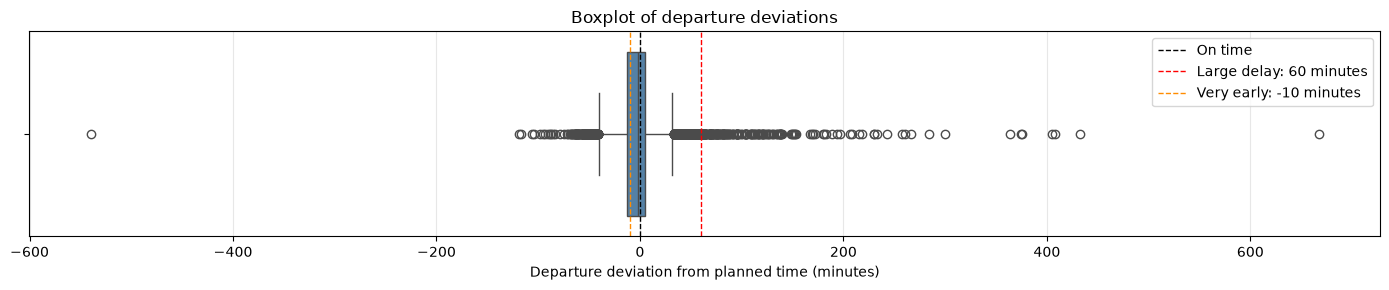

In [168]:
# Ensure the column is numeric
df_vy_timings_filtered["departure_delay"] = pd.to_numeric(
    df_vy_timings_filtered["departure_delay"],
    errors="coerce"
)

plt.figure(figsize=(14, 3))

sns.boxplot(
    x=df_vy_timings_filtered["departure_delay"],
    color="steelblue"
)

plt.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1,
    label="On time"
)

plt.axvline(
    60,
    color="red",
    linestyle="--",
    linewidth=1,
    label="Large delay: 60 minutes"
)

plt.axvline(
    -10,
    color="darkorange",
    linestyle="--",
    linewidth=1,
    label="Very early: -10 minutes"
)

plt.title("Boxplot of departure deviations")
plt.xlabel("Departure deviation from planned time (minutes)")
plt.legend()
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [169]:
delay = df_vy_timings_filtered["departure_delay"].dropna()

q1 = delay.quantile(0.25)
q3 = delay.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

boxplot_outliers = df_vy_timings_filtered[
    (df_vy_timings_filtered["departure_delay"] < lower_bound) |
    (df_vy_timings_filtered["departure_delay"] > upper_bound)
].sort_values("departure_delay")

print(f"Lower outlier bound: {lower_bound:.2f} minutes")
print(f"Upper outlier bound: {upper_bound:.2f} minutes")
print(f"Number of boxplot outliers: {len(boxplot_outliers)}")

boxplot_outliers[
    [
        "LoggTogID",
        "train_id",
        "train_date",
        "scheduled_departure_time",
        "actual_departure_time",
        "departure_delay"
    ]
]

Lower outlier bound: -40.00 minutes
Upper outlier bound: 32.00 minutes
Number of boxplot outliers: 565


,LoggTogID,train_id,train_date,scheduled_departure_time,actual_departure_time,departure_delay
14421,10-11-2025_5709,5709,2025-11-10,2025-11-10T20:12:00.000Z,2025-11-10T11:12:00.000Z,-540.0
1208,24-08-2026_91971,91971,2026-08-24,2026-08-24T11:36:00.000Z,2026-08-24T09:37:00.000Z,-119.0
1846,10-08-2026_5266,5266,2026-08-10,2026-08-10T10:54:00.000Z,2026-08-10T08:57:00.000Z,-117.0
1257,22-08-2026_85267,85267,2026-08-22,2026-08-22T21:40:00.000Z,2026-08-22T19:54:00.000Z,-106.0
2887,20-07-2026_5707,5707,2026-07-20,2026-07-20T15:12:00.000Z,2026-07-20T13:28:00.000Z,-104.0
...,...,...,...,...,...,...
19821,04-08-2025_5707,5707,2025-08-04,2025-08-04T15:12:00.000Z,2025-08-04T21:28:00.000Z,376.0
3100,15-07-2026_5707,5707,2026-07-15,2026-07-15T15:12:00.000Z,2026-07-15T21:57:00.000Z,405.0
7816,07-04-2026_4911,4911,2026-04-07,2026-04-07T07:22:00.000Z,2026-04-07T14:10:00.000Z,408.0
2992,17-07-2026_5735,5735,2026-07-17,2026-07-17T20:35:00.000Z,2026-07-18T03:48:00.000Z,433.0


##### Data types/formats

In [170]:
df_vy_timings_filtered.tail()

,train_id,train_date,cancelled,scheduled_departure_time,actual_departure_time,actual_arrival_time,estimated_arrival_time,just_passing_through,departure_delay,train_company,LoggTogID
19942,5735,2025-08-01,N,2025-08-01T20:42:00.000Z,2025-08-01T20:43:00.000Z,NaN,NaN,False,1.0,CN,01-08-2025_5735
19943,68340,2025-08-01,N,2025-08-01T18:26:00.000Z,2025-08-01T18:14:00.000Z,NaN,NaN,False,-12.0,CN,01-08-2025_68340
19945,81914,2025-08-01,N,2025-08-01T13:07:00.000Z,2025-08-01T12:48:00.000Z,NaN,NaN,False,-19.0,CN,01-08-2025_81914
19948,85805,2025-08-01,N,2025-08-01T11:30:00.000Z,2025-08-01T11:25:00.000Z,NaN,NaN,False,-5.0,CN,01-08-2025_85805
19950,85811,2025-08-01,N,2025-08-01T16:30:00.000Z,2025-08-01T16:30:00.000Z,NaN,NaN,False,0.0,CN,01-08-2025_85811


In [171]:
# Check data types
df_vy_timings_filtered.dtypes

train_id                             int64
train_date                  datetime64[us]
cancelled                              str
scheduled_departure_time               str
actual_departure_time                  str
actual_arrival_time                    str
estimated_arrival_time                 str
just_passing_through                  bool
departure_delay                    float64
train_company                          str
LoggTogID                              str
dtype: object

The selected columns mostly have suitable data types and formats for further analysis. `train_id` is numeric and should be converted to string, `train_date` is stored as a datetime, `just_passing_through` is Boolean, `departure_delay` is numeric, and `LoggTogID` follows the expected DD-MM-YYYY_train_id format. The `cancelled` and `train_company` columns contain categorical string values. The scheduled and actual departure times, together with the actual and estimated arrival times, are stored as ISO 8601 timestamp strings and should be converted to `Europe/Oslo` datetime before performing time-based calculations. The arrival columns are included to distinguish arrival-only trains from trains relevant to the departure analysis. Missing values in the time columns are handled separately in the missing-value analysis.

### Summary and final verdict of this dataset

The Vy timings dataset originally contained 19,952 rows covering the period from 01-08-2025 to 16-09-2026. After excluding cancelled trains, trains that were just passing through, and rows identified as arrival-only based on the arrival timestamps, 4,968 rows remained for the departure analysis. The arrival-only trains, comprising 4,597 rows, were stored separately for traceability.

The departure-analysis table represents 406 of 412 dates. The missing dates include dates where the available rows were arrival-only, as well as 04-04-2026 and 05-04-2026, which were checked against the terminal logs and had only cancelled trains. The missing dates are therefore explainable, but the date coverage should be documented clearly.

No blank rows or fully duplicate rows were found. `LoggTogID` is non-missing and should be unique for the 4,968 rows in the updated departure-analysis table. The grain is therefore one row per departure, provided that the uniqueness check is rerun after excluding the arrival-only rows.

The departure-time completeness check shows that 4,703 rows have both scheduled and actual departure times. A further 151 rows have a scheduled departure without a registered actual departure, while one row has an actual departure without a scheduled departure. The remaining 113 rows have neither departure time nor arrival time and require further investigation. The 4,597 rows with missing departure times and arrival information were identified as arrival-only trains and excluded from the departure analysis. No rows were found where both departure times were present but `departure_delay` was missing.

The departure-delay data contains extreme values. The boxplot identified 565 statistical outliers before arrival-only trains were excluded. This check should be rerun on the updated departure-analysis table so that the outlier count only describes actual departure records. The extreme observations should not be removed automatically, but investigated as possible operational edge cases or data-quality issues.

**Final verdict:** The dataset is suitable as a basis for departure analysis after distinguishing arrival-only trains from departure records. The updated departure-analysis table has the intended grain of one row per `LoggTogID`, subject to rerunning the uniqueness check after filtering. However, the 113 rows without either arrival or departure information, the 151 rows without an actual departure, the one row without a scheduled departure, and the extreme departure deviations should be handled explicitly before further analysis. The data types and timestamp formats should also be converted to the preferred variants.

## ExcelReport-6f2dcb04-d1bc-4d7e-b997-cbd3a93fe1b3


### Qualitative aspects

**Data collection procedure:** 
- A -- Automatically generated report from the TIOS systems, of all CargoNet delayed trains
- B -- Time data is automatically generated based on source data by sensors and internal systems at Bane NOR and in the infrastructure
- C -- Delay code and comments are inputted manually by TXP operator (traffic control at Bane NOR).

**Comment:**
- A & B -- The time data should be reliable and be able to represent actual delay time
- C -- The delay code might still be vulnerable to subjective interpretations of the TXP operator, but the comments might explain the reason of choosing the particular code.

**Relevant columns to use:**
- `Dato`
- `Tognr`
- `Innstilt`
- `Forsinkelse`
- `Årsak`
- `HL-beskrivelse`
- `Kommentar`

### Quantitative aspects

#### Preparation

In [172]:
# Import
df_TIOS_delays_report = pd.read_csv("../data/ExcelReport-6f2dcb04-d1bc-4d7e-b997-cbd3a93fe1b3.csv", sep=";", encoding="utf-8-sig")


In [173]:
# Define the inclusive date interval
start_date = pd.Timestamp("2025-08-01")
end_date = pd.Timestamp("2026-09-16")

# Convert Avgangsdato in both dataframes
df_TIOS_delays_report["Dato"] = pd.to_datetime(
    df_TIOS_delays_report["Dato"],
    format="%d.%m.%Y",
    errors="coerce"
)

# Filter the combined dataset based on time period
df_tios_delays_filtered = (
    df_TIOS_delays_report[
        df_TIOS_delays_report["Dato"].between(
            start_date,
            end_date,
            inclusive="both"
        )
    ]
    .copy()
    .reset_index(drop=True)
)

In [174]:
print("Number of rows:", len(df_tios_delays_filtered))
print(
    "Date range:",
    df_tios_delays_filtered["Dato"].min(),
    "to",
    df_tios_delays_filtered["Dato"].max()
)
print(df_tios_delays_filtered["Dato"].dtype)

Number of rows: 1816
Date range: 2025-08-01 00:00:00 to 2026-09-15 00:00:00
datetime64[us]


In [175]:
# Select the relevant columns for further analysis
relevant_columns = [
    "Dato",
    "Tognr",
    "Innstilt",
    "Forsinkelse",
    "Årsak",
    "HL-beskrivelse",
    "Kommentar"
]

df_tios_delays_filtered = (
    df_tios_delays_filtered[relevant_columns]
    .copy()
)

In [176]:
# Check filtering
print("Dimensions of filtered table:", df_tios_delays_filtered.shape)
df_tios_delays_filtered.columns.tolist()

Dimensions of filtered table: (1816, 7)


['Dato',
 'Tognr',
 'Innstilt',
 'Forsinkelse',
 'Årsak',
 'HL-beskrivelse',
 'Kommentar']

In [177]:
# Constructing the LoggTogID column
df_tios_delays_filtered["LoggTogID"] = (
    df_tios_delays_filtered["Dato"].dt.strftime("%d-%m-%Y")
    + "_"
    + df_tios_delays_filtered["Tognr"].astype(str)
)

df_tios_delays_filtered[["Tognr", "Dato", "LoggTogID"]].head()

,Tognr,Dato,LoggTogID
0,5507,2025-08-01,01-08-2025_5507
1,5507,2025-08-01,01-08-2025_5507
2,5737,2025-08-02,02-08-2025_5737
3,41971,2025-08-04,04-08-2025_41971
4,5531,2025-08-04,04-08-2025_5531


In [178]:
# Checking values of Innstilt (cancelled trains)
df_tios_delays_filtered["Innstilt"].value_counts(dropna=False)

Innstilt
Nei    1816
Name: count, dtype: int64

#### Actual analysis

##### Expected dates for analysis period
- All dates covered?
- Any gaps in the middle of the study period?

In [179]:
retained_daily_counts, retained_missing_dates = check_date_coverage(
    df=df_tios_delays_filtered,
    date_column="Dato",
    start_date=start_date,
    end_date=end_date,
    label="Retained trains"
)


Retained trains
---------------
Rows: 1816
Rows with missing dates: 0
Dates represented: 322 of 412
Dates with no records: 90
Missing dates:
['2025-08-03', '2025-08-09', '2025-08-14', '2025-08-16', '2025-08-18', '2025-08-23', '2025-08-24', '2025-08-30', '2025-08-31', '2025-09-13', '2025-09-14', '2025-09-27', '2025-10-05', '2025-10-11', '2025-10-18', '2025-10-19', '2025-10-25', '2025-11-08', '2025-11-09', '2025-11-16', '2025-11-22', '2025-11-29', '2025-12-06', '2025-12-07', '2025-12-13', '2025-12-14', '2025-12-20', '2025-12-21', '2025-12-24', '2025-12-25', '2025-12-26', '2025-12-27', '2025-12-31', '2026-01-01', '2026-01-03', '2026-01-10', '2026-01-17', '2026-01-24', '2026-02-01', '2026-02-07', '2026-02-08', '2026-02-20', '2026-02-21', '2026-02-22', '2026-02-28', '2026-03-06', '2026-03-07', '2026-03-08', '2026-03-14', '2026-04-02', '2026-04-03', '2026-04-04', '2026-04-05', '2026-04-06', '2026-04-11', '2026-04-18', '2026-04-25', '2026-04-26', '2026-05-01', '2026-05-02', '2026-05-03', '20

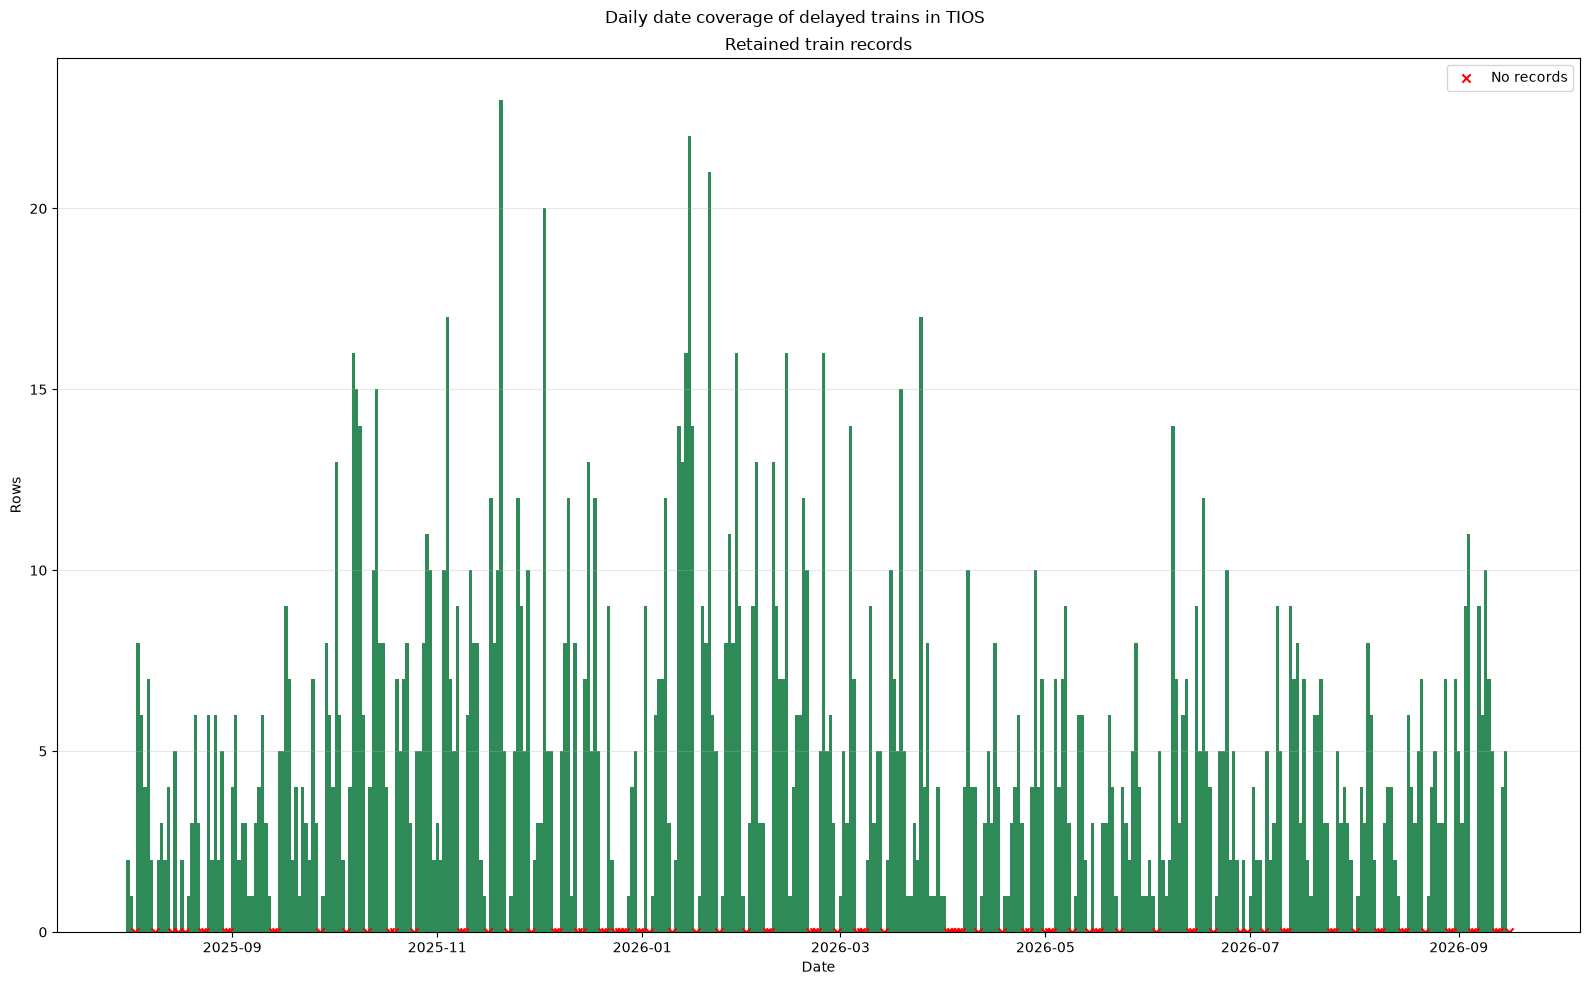

In [180]:
# Visualize the data

fig, axes = plt.subplots(
    nrows=1,
    ncols=1,
    figsize=(16, 10),
    sharex=True,
    squeeze=False
)

axes = axes.ravel()

datasets = [
    ("Retained train records", retained_daily_counts, "seagreen")
]

for ax, (label, daily_counts, color) in zip(axes, datasets):
    ax.bar(
        daily_counts.index,
        daily_counts["number_of_rows"],
        width=1.0,
        color=color
    )

    zero_dates = daily_counts.index[
        daily_counts["number_of_rows"] == 0
    ]

    ax.scatter(
        zero_dates,
        [0] * len(zero_dates),
        color="red",
        marker="x",
        s=35,
        label="No records"
    )

    ax.set_ylabel("Rows")
    ax.set_title(label)
    ax.grid(axis="y", alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Date")

plt.suptitle("Daily date coverage of delayed trains in TIOS")
plt.tight_layout()
plt.show()

*Comment:* Missing dates in this dataset is fine, as the dataset only has records for *delayed* trains - not all actual, departed trains from Alnabru.

##### Row level contents
- Blank rows?
- Duplicate rows?
- Rows w/o train ID (Tognummer)?
- Planned departures w/o actual departure times?
- Actual departures w/o planned departure?

In [181]:
# Duplicate rows
duplicate_rows = df_tios_delays_filtered[
    df_tios_delays_filtered.duplicated(keep=False)
]

print(f"Number of duplicate rows: {len(duplicate_rows)}")
duplicate_rows

Number of duplicate rows: 524


,Dato,Tognr,Innstilt,Forsinkelse,Årsak,HL-beskrivelse,Kommentar,LoggTogID
0,2025-08-01,5507,Nei,00:06,7.0,NaN,Kø / Trafikk / Øvrig toggang,01-08-2025_5507
1,2025-08-01,5507,Nei,00:06,7.0,NaN,Kø / Trafikk / Øvrig toggang,01-08-2025_5507
9,2025-08-04,8250,Nei,00:26,7.0,NaN,Annet,04-08-2025_8250
10,2025-08-04,8250,Nei,00:26,7.0,NaN,Annet,04-08-2025_8250
11,2025-08-05,41960,Nei,00:14,7.0,NaN,Kø / Trafikk / Øvrig toggang. 5734 ble ønsket ...,05-08-2025_41960
...,...,...,...,...,...,...,...,...
1784,2026-09-08,85511,Nei,00:15,7.0,NaN,Feil i ruteplan,08-09-2026_85511
1787,2026-09-09,5301,Nei,00:13,7.0,NaN,Annet,09-09-2026_5301
1788,2026-09-09,5301,Nei,00:13,7.0,NaN,Annet,09-09-2026_5301
1804,2026-09-11,5811,Nei,00:05,7.0,NaN,Feil i ruteplan,11-09-2026_5811


*Comment:* Duplicate rows need to be handled. It is sufficient to only keep one of the duplicate instances

In [182]:
# Blank rows
blank_rows = df_tios_delays_filtered[
    df_tios_delays_filtered
    .replace(r"^\s*$", pd.NA, regex=True)
    .isna()
    .all(axis=1)
]

print(f"Number of blank rows: {len(blank_rows)}")

Number of blank rows: 0


##### Column level contents - missing values
- For each relevant, chosen column ^^
- (Distignuish between if missing values are ok or not, e.g. punctual departures have no delay code)

In [183]:
df_check = df_tios_delays_filtered.copy()

df_check = df_check.replace(r"^\s*$", pd.NA, regex=True)

missing_summary = pd.DataFrame({
    "missing_count": df_check.isna().sum(),
    "missing_percentage": (
        df_check.isna().mean() * 100
    ).round(2),
    "data_type": df_check.dtypes.astype(str)
})

missing_summary

,missing_count,missing_percentage,data_type
Dato,0,0.00,datetime64[us]
Tognr,0,0.00,int64
Innstilt,0,0.00,str
Forsinkelse,0,0.00,str
Årsak,0,0.00,float64
HL-beskrivelse,1540,84.80,str
Kommentar,447,24.61,str
LoggTogID,0,0.00,str


##### Grain uniqueness and duplicates
*Note:* Duplicated rows identified by the earlier step will be handled before grain analysis.

In [184]:
# Count rows before removing exact duplicates
rows_before = len(df_tios_delays_filtered)

# Keep the first occurrence of each exact duplicate row
df_tios_delays_filtered = (
    df_tios_delays_filtered
    .drop_duplicates(keep="first")
    .reset_index(drop=True)
)

# Validate the result
rows_after = len(df_tios_delays_filtered)
duplicates_after = df_tios_delays_filtered.duplicated().sum()

print(f"Rows before removing duplicates: {rows_before}")
print(f"Rows after removing duplicates: {rows_after}")
print(f"Rows removed: {rows_before - rows_after}")
print(f"Remaining exact duplicate rows: {duplicates_after}")

Rows before removing duplicates: 1816
Rows after removing duplicates: 1554
Rows removed: 262
Remaining exact duplicate rows: 0


In [185]:
# Basic grain summary
grain_summary = pd.Series({
    "Number of rows": len(df_tios_delays_filtered),
    "Number of non-missing LoggTogID values": (
        df_tios_delays_filtered["LoggTogID"].notna().sum()
    ),
    "Number of unique LoggTogID values": (
        df_tios_delays_filtered["LoggTogID"].nunique()
    ),
    "Number of duplicated LoggTogID values": (
        df_tios_delays_filtered["LoggTogID"].duplicated().sum()
    ),
    "Number of missing LoggTogID values": (
        df_tios_delays_filtered["LoggTogID"].isna().sum()
    )
})

grain_summary

Number of rows                            1554
Number of non-missing LoggTogID values    1554
Number of unique LoggTogID values         1554
Number of duplicated LoggTogID values        0
Number of missing LoggTogID values           0
dtype: int64

In [186]:
duplicate_loggtogid_rows = df_tios_delays_filtered[
    df_tios_delays_filtered["LoggTogID"].duplicated(keep=False)
].sort_values("LoggTogID")

duplicate_loggtogid_rows

,Dato,Tognr,Innstilt,Forsinkelse,Årsak,HL-beskrivelse,Kommentar,LoggTogID


In [187]:
is_unique_grain = (
    df_tios_delays_filtered["LoggTogID"].notna().all()
    and df_tios_delays_filtered["LoggTogID"].is_unique
)

print(f"One row per departure: {is_unique_grain}")

One row per departure: True


##### Scope of edge cases
- Outliers
    - Very large delays
    - Very early departures (deviation from planned)

In [188]:
# Check the forsinkelse format
df_tios_delays_filtered["Forsinkelse"].head()

0    00:06
1    00:22
2    00:11
3    00:36
4    00:09
Name: Forsinkelse, dtype: str

In [189]:
# Clean the duration strings
duration_text = (
    df_tios_delays_filtered["Forsinkelse"]
    .astype("string")
    .str.strip()
)

# Extract optional sign, hours, and minutes
parts = duration_text.str.extract(
    r"^(?P<sign>-?)(?P<hours>\d+):(?P<minutes>[0-5]\d)$"
)

# Convert hh:mm to total minutes
df_tios_delays_filtered["Forsinkelse_minutter"] = (
    parts["sign"].eq("-").where(parts["sign"].notna(), False)
    * -2
    + 1
) * (
    pd.to_numeric(parts["hours"], errors="coerce") * 60
    + pd.to_numeric(parts["minutes"], errors="coerce")
)

# Keep only valid values
forsinkelse_minutter = (
    df_tios_delays_filtered["Forsinkelse_minutter"]
    # .dropna()
)

print(forsinkelse_minutter.head())
print(f"Valid durations: {len(forsinkelse_minutter)}")

0     6
1    22
2    11
3    36
4     9
Name: Forsinkelse_minutter, dtype: Int64
Valid durations: 1554


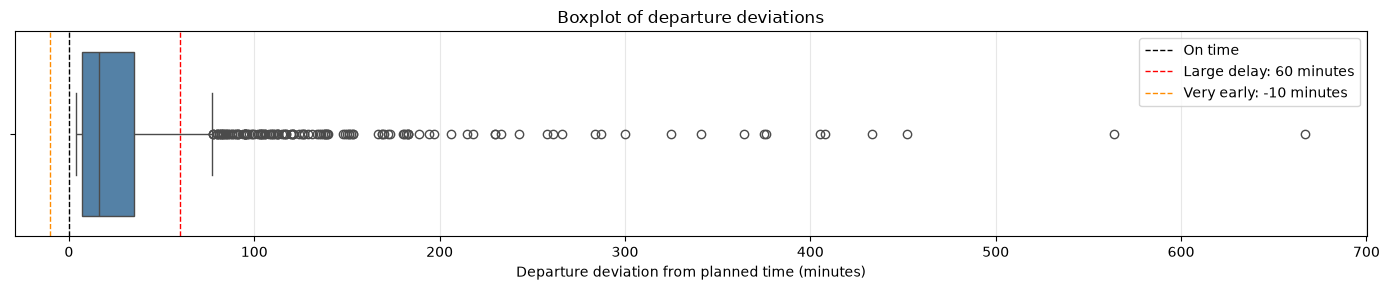

In [190]:
plt.figure(figsize=(14, 3))

sns.boxplot(
    x=forsinkelse_minutter.to_numpy(),
    color="steelblue"
)

plt.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1,
    label="On time"
)

plt.axvline(
    60,
    color="red",
    linestyle="--",
    linewidth=1,
    label="Large delay: 60 minutes"
)

plt.axvline(
    -10,
    color="darkorange",
    linestyle="--",
    linewidth=1,
    label="Very early: -10 minutes"
)

plt.title("Boxplot of departure deviations")
plt.xlabel("Departure deviation from planned time (minutes)")
plt.legend()
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [191]:
# Use the numeric delay values created from the hh:mm strings
delay = (
    df_tios_delays_filtered["Forsinkelse_minutter"]
    .dropna()
)

q1 = delay.quantile(0.25)
q3 = delay.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# Keep the complete rows identified as statistical outliers
boxplot_outliers = (
    df_tios_delays_filtered[
        (
            df_tios_delays_filtered["Forsinkelse_minutter"]
            < lower_bound
        )
        |
        (
            df_tios_delays_filtered["Forsinkelse_minutter"]
            > upper_bound
        )
    ]
    .sort_values("Forsinkelse_minutter")
)

print(f"Q1: {q1:.2f} minutes")
print(f"Q3: {q3:.2f} minutes")
print(f"IQR: {iqr:.2f} minutes")
print(f"Lower outlier bound: {lower_bound:.2f} minutes")
print(f"Upper outlier bound: {upper_bound:.2f} minutes")
print(f"Number of boxplot outliers: {len(boxplot_outliers)}")

boxplot_outliers[
    [
        "LoggTogID",
        "Tognr",
        "Dato",
        "Forsinkelse",
        "Forsinkelse_minutter",
        "Årsak",
        "Kommentar",
    ]
]

Q1: 7.00 minutes
Q3: 35.00 minutes
IQR: 28.00 minutes
Lower outlier bound: -35.00 minutes
Upper outlier bound: 77.00 minutes
Number of boxplot outliers: 135


,LoggTogID,Tognr,Dato,Forsinkelse,Forsinkelse_minutter,Årsak,Kommentar
346,05-11-2025_5733,5733,2025-11-05,01:18,78,1.0,Annet. Tavlelogg: feil på kran Alnabru
594,06-01-2026_41971,41971,2026-01-06,01:18,78,99.0,Annet. Tavlelogg: sent lok til stamme. Ukjent ...
1170,15-05-2026_44800,44800,2026-05-15,01:18,78,82.0,Måtte vente på 8254.
528,16-12-2025_5515,5515,2025-12-16,01:20,80,99.0,Kø/Trafikk/Øvrig toggang. Tavlelog: Trafikkavv...
889,19-02-2026_5709,5709,2026-02-19,01:20,80,2.0,Sporveksel/-sperre ikke i kontroll. problemer ...
...,...,...,...,...,...,...,...
1049,07-04-2026_4911,4911,2026-04-07,06:48,408,93.0,Avsporing
1371,17-07-2026_5735,5735,2026-07-17,07:13,433,3.0,Annet
1370,17-07-2026_5709,5709,2026-07-17,07:32,452,3.0,Annet
1367,17-07-2026_41900,41900,2026-07-17,09:24,564,3.0,Annet


##### Data types/formats

In [192]:
# Check data types
df_tios_delays_filtered.dtypes

Dato                    datetime64[us]
Tognr                            int64
Innstilt                           str
Forsinkelse                        str
Årsak                          float64
HL-beskrivelse                     str
Kommentar                          str
LoggTogID                          str
Forsinkelse_minutter             Int64
dtype: object

The selected columns have suitable formats for further analysis. `Dato` is stored as a datetime and can be used directly for date-based grouping and coverage checks. `Tognr` is currently stored as an integer and may be converted to a string because it is an identifier rather than a numerical measurement; this also prevents any potential loss of leading zeros. `Innstilt`, `HL-beskrivelse`, and `Kommentar` are categorical/text fields, while `LoggTogID` is a string identifier following the expected date–train-number format. `Årsak` is stored as `float64`, which should be converted into `str` as it is a categorical column. `Forsinkelse` is stored as an `hh:mm` string and was converted to `Forsinkelse_minutter`, which is stored as nullable integer data (`Int64`) and is suitable for numerical calculations, visualizations, and outlier analysis. Missing values in the descriptive and delay-related columns should be assessed separately, as some may be expected—for example, missing reason descriptions for records without an assigned reason code.

### Summary and final verdict of this dataset

The TIOS ExcelReport dataset contains 1,816 delayed-train records covering 01-08-2025 to 15-09-2026. All records have `Innstilt = "Nei"`, meaning that cancelled trains are not included. After removing 524 rows identified as exact duplicates, 1,554 records remain for analysis.

The dataset represents 322 of 412 dates in the defined analysis period. The 90 dates without records are explainable because the dataset contains delayed trains only, but the incomplete date coverage should be documented.

No blank rows were found. The essential fields are complete, including `Dato`, `Tognr`, `Forsinkelse`, `Årsak`, and `LoggTogID`. However, `HL-beskrivelse` is missing in 1,540 rows and `Kommentar` is missing in 447 rows. However, these columns are only explanatory and might only provide extra information about nuances.

The delay data contains 135 outliers above the upper limit of 77 minutes. These observations should be investigated as potential operational edge cases rather than removed automatically. The `hh:mm` delay values have been converted to `Forsinkelse_minutter` for numerical analysis.

**Final verdict:** The dataset is suitable for analysing registered train delays after removing exact duplicates and verifying the uniqueness of `LoggTogID`. However, it represents delayed trains only and cannot be used as a complete overview of all train departures. The incomplete date coverage, missing descriptive fields, and extreme delay observations should be documented and handled explicitly before further analysis.

## Årsakskodelister (IKKE REDIGER!

### Qualitative aspects

**Data collection procedure:** 
- A -- This is a static mapping table of the CargoNet terminal codes to the TIOS codes provided by Bane NOR.
- B -- The codes are made and mapped by CargoNet themselves

**Comment:**
- This is only a mapping of the codes, no actual data to analyze. The mapping will complement the other datasets, and might be used for triangulating between the CargoNet terminal logs and the TIOS delay data.

### Quantitative aspects

#### Preparation

In [193]:
# Import
df_aarsakskodeliste = pd.read_csv("../data/Årsakskodelister (IKKE REDIGER!.csv", sep=";", encoding="utf-8-sig")

df_aarsakskodeliste

,Kode,Kort beskrivelse,Nedtrekks-tekst,Tilhørende YtelsesordningKode
0,T1,I rute,T1 - I rute,NaN
1,T2,Nytt tognummer (Skriv det nye i kommentar),T2 - Nytt tognummer (Skriv det nye i kommentar),Kode 7 - Trafikkavvikling (Infrastrukturs andel)
2,T3,Lokfører,T3 - Lokfører,Kode 83 - Manglende personell
3,T4,Forsinket ankommet tog. (kort snutid),T4 - Forsinket ankommet tog. (kort snutid),Kode 82 - Kjøretøy sent fra hensettingsspor
4,T5,Vognmangel,T5 - Vognmangel,Kode 85 - Planforutsetninger ikke oppfylt
5,T6,De-icing,T6 - De-icing,Kode 85 - Planforutsetninger ikke oppfylt
6,T7,Graving av snø,T7 - Graving av snø,Kode 92 - Ytre forhold
7,T8,Maskinmangel skifting,T8 - Maskinmangel skifting,Kode 84 - Stasjonsopphold
8,T9,Feil på vogn,T9 - Feil på vogn,Kode 81 - Feil ved kjøretøy
9,T10,Overbooking,T10 - Overbooking,Kode 85 - Planforutsetninger ikke oppfylt


#### Actual analysis

##### Data types/formats

In [194]:
# Check data types
df_aarsakskodeliste.dtypes

Kode                             str
Kort beskrivelse                 str
Nedtrekks-tekst                  str
Tilhørende YtelsesordningKode    str
dtype: object

##### Row level contents
- Blank rows?
- Duplicate rows?
- Rows w/o train ID (Tognummer)?
- Planned departures w/o actual departure times?
- Actual departures w/o planned departure?

In [195]:
# Duplicate rows
duplicate_rows = df_aarsakskodeliste[
    df_aarsakskodeliste.duplicated(keep=False)
]

print(f"Number of duplicate rows: {len(duplicate_rows)}")
duplicate_rows

Number of duplicate rows: 0


,Kode,Kort beskrivelse,Nedtrekks-tekst,Tilhørende YtelsesordningKode


In [196]:
# Blank rows
blank_rows = df_aarsakskodeliste[
    df_aarsakskodeliste
    .replace(r"^\s*$", pd.NA, regex=True)
    .isna()
    .all(axis=1)
]

print(f"Number of blank rows: {len(blank_rows)}")

Number of blank rows: 0


##### Column level contents - missing values
- For each relevant, chosen column ^^
- (Distignuish between if missing values are ok or not, e.g. punctual departures have no delay code)

In [197]:
df_check = df_aarsakskodeliste.copy()

df_check = df_check.replace(r"^\s*$", pd.NA, regex=True)

missing_summary = pd.DataFrame({
    "missing_count": df_check.isna().sum(),
    "missing_percentage": (
        df_check.isna().mean() * 100
    ).round(2),
    "data_type": df_check.dtypes.astype(str)
})

missing_summary

,missing_count,missing_percentage,data_type
Kode,0,0.00,str
Kort beskrivelse,0,0.00,str
Nedtrekks-tekst,0,0.00,str
Tilhørende YtelsesordningKode,1,2.94,str


*Comment:* The missing `TilhørendeYtelsesordningKode` is the terminal code for "T1 - I rute" and can be ignored as it isn't actually a code for delays

##### Grain uniqueness and duplicates

*Comment:* This table is purely a dimension table, and a grain of each row being a train departure is not applicable or relevant here.

### Summary and final verdict of this dataset

The Årsakskodelister dataset is a static mapping table containing 34 reason codes and their corresponding descriptions and performance categories. No blank rows or duplicate rows were found, and all codes and descriptions are complete. The single missing performance-category mapping belongs to T1 - I rute, which is not a delay code and is therefore acceptable.

**Final verdict:** The dataset is suitable for use as a reference and mapping table for the TIOS delay and terminal-log datasets.

## Terminallogg R25 and R26
*Combined R25 and R26 datasets as a result of the findings of the data exploration*

### Qualitative aspects

**Data collection procedure:** 
- A -- Content should contain all expected CargoNet train departures from Alnabru in the R25 and R26 calendar
- B -- Input data are mostly done manually in excel-sheets
- C -- Excel columns have strict data validation turned on to ensure proper formats
- D -- Some columns are calculated automatically using formulas (f.eks. the ones regarding 'Avvik' and 'LoggTogID')  

**Comment:**
- A -- the datasets works as a basis of which train departures to analyze, i.e. the datasets here are the ones to analyze for R25 and R26
- B & C -- The input is done manually and not automatically, and only the formatting is validated, not the actual content of the values. That makes the input values still vulnerable for wrong input values, typos, operator faults and/or routines for consistent/standardized inputs. This especially goes for timestamps, where one should do a quantitative assesment as well, to check the scope of data quality issues regarding the actual inputs. 
The 'Årsakskode'-column have more strict validation where users must choose from a list and can be considered to have a higher probability of "correct" input values, although the choice of code is done by the operator and thus dependent/vulnerable on their subjective interpretation.
- D -- The automatically calculated columns are dependent on input of other columns. These might still be used, but the formulas from here can easily be replicated and might rather be calculated again in this study for consistent calculations. 

**Relevant columns to use:**
- `Merknad`
- `Tognummer`
- `Avgangsdato`
- `Lastefrist`
- `Ferdig opplastet`
- `Frist lok`
- `Lok ankommet`
- `Planlagt klart fra terminal`
- `Klart fra terminal`
- `Planlagt avgang`
- `Faktisk avgang`
- `Årsakskode - avgangsforsinkelse`
- `Kommentar`
- `LoggTogID`

### Quantitative aspects

#### Preparation

In [198]:
# Import both datasets
df_terminallogg_r25 = pd.read_csv(
    "../data/Terminallogg R25.csv",
    sep=";",
    encoding="utf-8-sig"
)

df_terminallogg_r26 = pd.read_csv(
    "../data/Terminallogg R26.csv",
    sep=";",
    encoding="utf-8-sig"
)

In [199]:
print(df_terminallogg_r25.shape)
print(df_terminallogg_r26.shape)

(5169, 23)
(5242, 23)


In [200]:
# Define the inclusive date interval
start_date = pd.Timestamp("2025-08-01")
end_date = pd.Timestamp("2026-09-16")

# Convert Avgangsdato in both dataframes
df_terminallogg_r25["Avgangsdato"] = pd.to_datetime(
    df_terminallogg_r25["Avgangsdato"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce",
)

df_terminallogg_r26["Avgangsdato"] = pd.to_datetime(
    df_terminallogg_r26["Avgangsdato"],
    format="%Y-%m-%d",
    errors="coerce",
)

# Combine the datasets
df_terminallogg = pd.concat(
    [df_terminallogg_r25, df_terminallogg_r26],
    ignore_index=True,
)

# Filter the combined dataset based on time period
df_terminallogg_filtered = (
    df_terminallogg[
        df_terminallogg["Avgangsdato"].between(
            start_date,
            end_date,
            inclusive="both"
        )
    ]
    .copy()
    .reset_index(drop=True)
)

In [201]:
print("Number of rows:", len(df_terminallogg_filtered))
print(
    "Date range:",
    df_terminallogg_filtered["Avgangsdato"].min(),
    "to",
    df_terminallogg_filtered["Avgangsdato"].max()
)
print(df_terminallogg_filtered["Avgangsdato"].dtype)

Number of rows: 6065
Date range: 2025-08-01 00:00:00 to 2026-09-16 00:00:00
datetime64[us]


In [202]:
# Select the relevant columns for further analysis
relevant_columns = [
    "Merknad",
    "Tognummer",
    "Avgangsdato",
    "Lastefrist",
    "Ferdig opplastet",
    "Frist lok",
    "Lok ankommet",
    "Planlagt klart fra terminal",
    "Klart fra terminal",
    "Planlagt avgang",
    "Faktisk avgang",
    "Årsakskode - avgangsforsinkelse",
    "Kommentar",
    "LoggTogID"
]

df_terminallogg_filtered = (
    df_terminallogg_filtered[relevant_columns]
    .copy()
)

In [203]:
# Check filtering
print("Dimensions of filtered table:", df_terminallogg_filtered.shape)
df_terminallogg_filtered.columns.tolist()

Dimensions of filtered table: (6065, 14)


['Merknad',
 'Tognummer',
 'Avgangsdato',
 'Lastefrist',
 'Ferdig opplastet',
 'Frist lok',
 'Lok ankommet',
 'Planlagt klart fra terminal',
 'Klart fra terminal',
 'Planlagt avgang',
 'Faktisk avgang',
 'Årsakskode - avgangsforsinkelse',
 'Kommentar',
 'LoggTogID']

*Comment:* Analysis should not use cancelled trains

In [204]:
# Checking values of cancelled train with the Årsakskode "T17 - Innstilt tog"
print("Number of cancelled rows:",
    (
        df_terminallogg_filtered["Årsakskode - avgangsforsinkelse"]
        == "T17 - Innstilt tog"
    ).sum()
)

Number of cancelled rows: 816


In [205]:
# Store the rows with cancelled trains
df_terminallog_cancelled_trains = (df_terminallogg_filtered[
    df_terminallogg_filtered["Årsakskode - avgangsforsinkelse"] == "T17 - Innstilt tog"
    ]).copy()

df_terminallog_cancelled_trains.shape

(816, 14)

In [206]:
# Filter out cancelled trains
df_terminallogg_filtered= (
    df_terminallogg_filtered[
        df_terminallogg_filtered["Årsakskode - avgangsforsinkelse"]
        != "T17 - Innstilt tog"
    ]
    .copy()
    .reset_index(drop=True)
)

# Check filtering
print("Dimensions of filtered table:", df_terminallogg_filtered.shape)
df_terminallogg_filtered.columns.tolist()

Dimensions of filtered table: (5249, 14)


['Merknad',
 'Tognummer',
 'Avgangsdato',
 'Lastefrist',
 'Ferdig opplastet',
 'Frist lok',
 'Lok ankommet',
 'Planlagt klart fra terminal',
 'Klart fra terminal',
 'Planlagt avgang',
 'Faktisk avgang',
 'Årsakskode - avgangsforsinkelse',
 'Kommentar',
 'LoggTogID']

In [207]:
# Checking values of cancelled train with the Årsakskode "T17 - Innstilt tog" after filtering
print("Number of cancelled rows:",
    (
        df_terminallogg_filtered["Årsakskode - avgangsforsinkelse"]
        == "T17 - Innstilt tog"
    ).sum()
)

Number of cancelled rows: 0


#### Actual analysis

##### Expected dates for analysis period
- All dates covered?
- Any gaps in the middle of the study period?

In [208]:
cancelled_daily_counts, cancelled_missing_dates = check_date_coverage(
    df=df_terminallog_cancelled_trains,
    date_column="Avgangsdato",
    start_date=start_date,
    end_date=end_date,
    label="Cancelled trains"
)

retained_daily_counts, retained_missing_dates = check_date_coverage(
    df=df_terminallogg_filtered,
    date_column="Avgangsdato",
    start_date=start_date,
    end_date=end_date,
    label="Retained trains"
)


Cancelled trains
----------------
Rows: 816
Rows with missing dates: 0
Dates represented: 268 of 412
Dates with no records: 144
Missing dates:
['2025-08-09', '2025-08-16', '2025-09-01', '2025-09-02', '2025-09-03', '2025-09-12', '2025-09-27', '2025-10-01', '2025-10-04', '2025-10-20', '2025-10-21', '2025-10-27', '2025-10-28', '2025-11-03', '2025-11-04', '2025-11-05', '2025-11-06', '2025-11-12', '2025-11-18', '2025-11-24', '2025-11-25', '2025-11-26', '2025-11-27', '2025-12-01', '2025-12-02', '2025-12-03', '2025-12-04', '2025-12-09', '2025-12-10', '2025-12-11', '2025-12-15', '2025-12-16', '2025-12-17', '2025-12-18', '2025-12-19', '2025-12-24', '2025-12-29', '2025-12-30', '2025-12-31', '2026-01-01', '2026-01-02', '2026-01-03', '2026-01-04', '2026-01-05', '2026-01-06', '2026-01-11', '2026-01-18', '2026-01-25', '2026-02-01', '2026-02-03', '2026-02-04', '2026-02-08', '2026-02-09', '2026-02-10', '2026-02-11', '2026-02-13', '2026-02-14', '2026-02-15', '2026-02-16', '2026-02-22', '2026-02-23', '

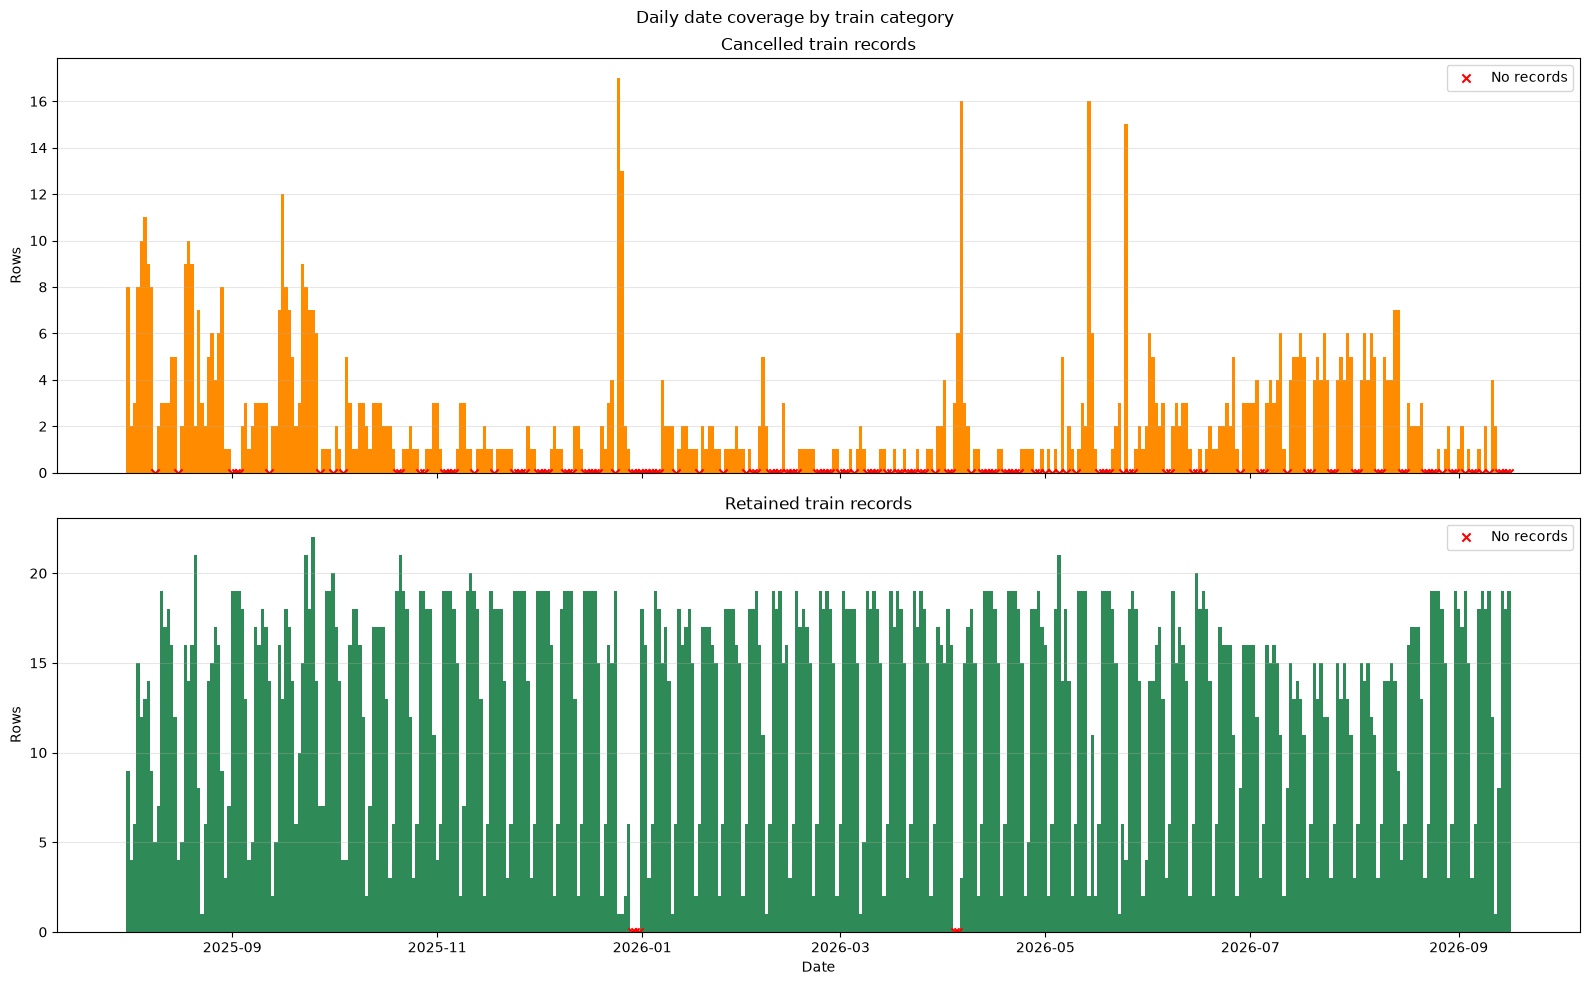

In [209]:
# Visualize the data

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(16, 10),
    sharex=True
)

datasets = [
    ("Cancelled train records", cancelled_daily_counts, "darkorange"),
    ("Retained train records", retained_daily_counts, "seagreen")
]

for ax, (label, daily_counts, color) in zip(axes, datasets):
    ax.bar(
        daily_counts.index,
        daily_counts["number_of_rows"],
        width=1.0,
        color=color
    )

    zero_dates = daily_counts.index[
        daily_counts["number_of_rows"] == 0
    ]

    ax.scatter(
        zero_dates,
        [0] * len(zero_dates),
        color="red",
        marker="x",
        s=35,
        label="No records"
    )

    ax.set_ylabel("Rows")
    ax.set_title(label)
    ax.grid(axis="y", alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Date")

plt.suptitle("Daily date coverage by train category")
plt.tight_layout()
plt.show()

*Comment:* The last 3 days of 2025 are missing completely.

##### Row level contents
- Blank rows?
- Duplicate rows?
- Rows w/o train ID (Tognummer)?
- Planned departures w/o actual departure times?
- Actual departures w/o planned departure?

In [210]:
# Duplicate rows
duplicate_rows = df_terminallogg_filtered[
    df_terminallogg_filtered.duplicated(keep=False)
]

print(f"Number of duplicate rows: {len(duplicate_rows)}")
duplicate_rows

Number of duplicate rows: 13


,Merknad,Tognummer,Avgangsdato,Lastefrist,Ferdig opplastet,Frist lok,Lok ankommet,Planlagt klart fra terminal,Klart fra terminal,Planlagt avgang,Faktisk avgang,Årsakskode - avgangsforsinkelse,Kommentar,LoggTogID
1837,NaN,NaN,2025-09-20,NaN,NaN,1899-12-29 23:20:00,NaN,1899-12-29 23:55:00,NaN,NaN,NaN,NaN,NaN,20-09-2025_
1838,NaN,NaN,2025-09-20,NaN,NaN,1899-12-29 23:20:00,NaN,1899-12-29 23:55:00,NaN,NaN,NaN,NaN,NaN,20-09-2025_
1841,NaN,NaN,2025-09-21,NaN,NaN,1899-12-29 23:20:00,NaN,1899-12-29 23:55:00,NaN,NaN,NaN,NaN,NaN,21-09-2025_
1842,NaN,NaN,2025-09-21,NaN,NaN,1899-12-29 23:20:00,NaN,1899-12-29 23:55:00,NaN,NaN,NaN,NaN,NaN,21-09-2025_
1843,NaN,NaN,2025-09-21,NaN,NaN,1899-12-29 23:20:00,NaN,1899-12-29 23:55:00,NaN,NaN,NaN,NaN,NaN,21-09-2025_
1844,NaN,NaN,2025-09-21,NaN,NaN,1899-12-29 23:20:00,NaN,1899-12-29 23:55:00,NaN,NaN,NaN,NaN,NaN,21-09-2025_
1858,NaN,NaN,2025-09-23,NaN,NaN,1899-12-29 23:20:00,NaN,1899-12-29 23:55:00,NaN,NaN,NaN,NaN,NaN,23-09-2025_
1859,NaN,NaN,2025-09-23,NaN,NaN,1899-12-29 23:20:00,NaN,1899-12-29 23:55:00,NaN,NaN,NaN,NaN,NaN,23-09-2025_
1860,NaN,NaN,2025-09-23,NaN,NaN,1899-12-29 23:20:00,NaN,1899-12-29 23:55:00,NaN,NaN,NaN,NaN,NaN,23-09-2025_
1874,NaN,NaN,2025-09-25,NaN,NaN,1899-12-29 23:20:00,NaN,1899-12-29 23:55:00,NaN,NaN,NaN,NaN,NaN,25-09-2025_


In [211]:
# Blank rows
blank_rows = df_terminallogg_filtered[
    df_terminallogg_filtered
    .replace(r"^\s*$", pd.NA, regex=True)
    .isna()
    .all(axis=1)
]

print(f"Number of blank rows: {len(blank_rows)}")

Number of blank rows: 0


In [212]:
# Checking rows w/o ID (Tognummer)
missing_train_id = (
    df_terminallogg_filtered["Tognummer"].isna()
    | df_terminallogg_filtered["Tognummer"].astype("string").str.strip().eq("")
)

print("Rows without tognummer:", missing_train_id.sum())

Rows without tognummer: 16


In [213]:
df_without_train_id = df_terminallogg_filtered.loc[missing_train_id].copy()
df_without_train_id

,Merknad,Tognummer,Avgangsdato,Lastefrist,Ferdig opplastet,Frist lok,Lok ankommet,Planlagt klart fra terminal,Klart fra terminal,Planlagt avgang,Faktisk avgang,Årsakskode - avgangsforsinkelse,Kommentar,LoggTogID
1837,NaN,NaN,2025-09-20,NaN,NaN,1899-12-29 23:20:00,NaN,1899-12-29 23:55:00,NaN,NaN,NaN,NaN,NaN,20-09-2025_
1838,NaN,NaN,2025-09-20,NaN,NaN,1899-12-29 23:20:00,NaN,1899-12-29 23:55:00,NaN,NaN,NaN,NaN,NaN,20-09-2025_
1841,NaN,NaN,2025-09-21,NaN,NaN,1899-12-29 23:20:00,NaN,1899-12-29 23:55:00,NaN,NaN,NaN,NaN,NaN,21-09-2025_
1842,NaN,NaN,2025-09-21,NaN,NaN,1899-12-29 23:20:00,NaN,1899-12-29 23:55:00,NaN,NaN,NaN,NaN,NaN,21-09-2025_
1843,NaN,NaN,2025-09-21,NaN,NaN,1899-12-29 23:20:00,NaN,1899-12-29 23:55:00,NaN,NaN,NaN,NaN,NaN,21-09-2025_
1844,NaN,NaN,2025-09-21,NaN,NaN,1899-12-29 23:20:00,NaN,1899-12-29 23:55:00,NaN,NaN,NaN,NaN,NaN,21-09-2025_
1858,NaN,NaN,2025-09-23,NaN,NaN,1899-12-29 23:20:00,NaN,1899-12-29 23:55:00,NaN,NaN,NaN,NaN,NaN,23-09-2025_
1859,NaN,NaN,2025-09-23,NaN,NaN,1899-12-29 23:20:00,NaN,1899-12-29 23:55:00,NaN,NaN,NaN,NaN,NaN,23-09-2025_
1860,NaN,NaN,2025-09-23,NaN,NaN,1899-12-29 23:20:00,NaN,1899-12-29 23:55:00,NaN,NaN,NaN,NaN,NaN,23-09-2025_
1866,NaN,NaN,2025-09-24,NaN,NaN,1899-12-29 23:20:00,NaN,1899-12-29 23:55:00,NaN,NaN,NaN,NaN,NaN,24-09-2025_


*Comment:* These rows, which are missing tognummer, are completely empty rows and will be removed.

In [214]:
# Check invalid tognummer formats
invalid_train_numbers = df_terminallogg_filtered[
    df_terminallogg_filtered["Tognummer"].notna()
    & (
        pd.to_numeric(
            df_terminallogg_filtered["Tognummer"],
            errors="coerce",
        ).isna()
    )
]

print("Rows with invalid train numbers:",
      len(invalid_train_numbers))

Rows with invalid train numbers: 0


In [215]:
# Comparing planned and actual departure times

scheduled_missing = (
    df_terminallogg_filtered["Planlagt avgang"].isna()
)

actual_missing = (
    df_terminallogg_filtered["Faktisk avgang"].isna()
)

# Planned departure exists, but actual departure is missing
planned_without_actual = df_terminallogg_filtered[
    ~scheduled_missing & actual_missing
]

# Actual departure exists, but planned departure is missing
actual_without_planned = df_terminallogg_filtered[
    scheduled_missing & ~actual_missing
]

print(
    "Planned departures without actual departure time:",
    len(planned_without_actual),
)

print(
    "Actual departures without planned departure time:",
    len(actual_without_planned),
)

Planned departures without actual departure time: 427
Actual departures without planned departure time: 4


In [216]:
planned_without_actual

,Merknad,Tognummer,Avgangsdato,Lastefrist,Ferdig opplastet,Frist lok,Lok ankommet,Planlagt klart fra terminal,Klart fra terminal,Planlagt avgang,Faktisk avgang,Årsakskode - avgangsforsinkelse,Kommentar,LoggTogID
21,NaN,45960.0,2025-08-04,14:00,NaN,15:02:00,NaN,15:37:00,NaN,15:42:00,NaN,NaN,NaN,04-08-2025_45960
74,NaN,5507.0,2025-08-08,"0,486",NaN,11:43:00,NaN,12:18:00,NaN,12:23:00,NaN,T1 - I rute,NaN,08-08-2025_5507
84,PRI-TOG,41910.0,2025-08-09,"0,732",NaN,17:45:00,NaN,18:20:00,NaN,18:25:00,NaN,NaN,NaN,09-08-2025_41910
95,Lastefristkl. 19:30 dag før avgang.,5301.0,2025-08-11,19:30:00,NaN,08:11:00,NaN,08:46:00,NaN,08:51:00,NaN,"T34 - Annen feil, forklaring i kommentarfelt",Tidligere avgangstid,11-08-2025_5301
99,NaN,5805.0,2025-08-11,16:00:00,NaN,16:11:00,NaN,16:46:00,NaN,16:51:00,NaN,T2 - Nytt tognummer (Skriv det nye i kommentar),"85805, Tidligere avgangstid.",11-08-2025_5805
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5242,PRI-TOG,41900.0,2026-09-16,19:40:00,NaN,19:46:00,NaN,20:21:00,NaN,20:26:00,NaN,NaN,NaN,16-09-2026_41900
5243,NaN,5709.0,2026-09-16,21:00:00,NaN,21:02:00,NaN,21:37:00,NaN,21:42:00,NaN,NaN,NaN,16-09-2026_5709
5244,LANGTOG,5811.0,2026-09-16,20:30:00,NaN,20:51:00,NaN,21:26:00,NaN,21:31:00,NaN,NaN,NaN,16-09-2026_5811
5245,LANGTOG,5515.0,2026-09-16,21:15:00,NaN,21:17:00,NaN,21:52:00,NaN,21:57:00,NaN,NaN,NaN,16-09-2026_5515


*Comment:* Note that some timestamps are in the wrong formats, e.g. row 74 and 84 in the `Lastefrist` column.

In [217]:
actual_without_planned

,Merknad,Tognummer,Avgangsdato,Lastefrist,Ferdig opplastet,Frist lok,Lok ankommet,Planlagt klart fra terminal,Klart fra terminal,Planlagt avgang,Faktisk avgang,Årsakskode - avgangsforsinkelse,Kommentar,LoggTogID
2058,NaN,4911.0,2026-01-08,07:00:00,07:00:00,08:42:00,08:42:00,08:17:00,08:13:00,NaN,09:23:00,NaN,NaN,08-01-2026_4911
2331,PRI-TOG,5735.0,2026-01-29,21:50:00,22:30:00,1899-12-29 23:20:00,NaN,1899-12-29 23:55:00,03:09:00,NaN,03:11:00,T18 - Sent lok til stamme,"mangel på lok, kommer i enten 5510 eller 41913",29-01-2026_5735
3310,NaN,4911.0,2026-04-14,08:50:00,08:50:00,08:50:00,08:50:00,09:17:00,09:10:00,NaN,09:30:00,T20 - Trafikkstyring (TXP/Togleder),Kø i syd. Lok og skifting.,14-04-2026_4911
3408,NaN,4911.0,2026-04-21,NaN,NaN,08:40:00,08:20:00,1899-12-29 23:55:00,NaN,NaN,09:10:00,NaN,Avgtid: 09:22.,21-04-2026_4911


In [218]:
# Check invalid time formats
time_columns = [
    "Lastefrist",
    "Ferdig opplastet",
    "Frist lok",
    "Lok ankommet",
    "Planlagt klart fra terminal",
    "Klart fra terminal",
    "Planlagt avgang",
    "Faktisk avgang",
]

invalid_time_summary = {}

for column in time_columns:
    parsed_time = pd.to_datetime(
        df_terminallogg_filtered[column],
        format="%H:%M:%S",
        errors="coerce",
    )

    invalid_time_summary[column] = (
        df_terminallogg_filtered[column].notna()
        & parsed_time.isna()
    ).sum()

invalid_time_summary

{'Lastefrist': np.int64(902),
 'Ferdig opplastet': np.int64(1),
 'Frist lok': np.int64(20),
 'Lok ankommet': np.int64(0),
 'Planlagt klart fra terminal': np.int64(20),
 'Klart fra terminal': np.int64(1),
 'Planlagt avgang': np.int64(0),
 'Faktisk avgang': np.int64(1)}

*Comment:* The parentheses show how many values deviates from the standard timestamp formats. Most of them have few wrong inputs, but `Lastefrist` here again has several invalid timestamp values. This is might be a major formatting or data-quality issue.

In [219]:
# Inspect the rows with wrong format in "Lastefrist"
column = "Lastefrist"

parsed_time = pd.to_datetime(
    df_terminallogg_filtered[column],
    format="%H:%M:%S",
    errors="coerce",
)

invalid_values = df_terminallogg_filtered.loc[
    df_terminallogg_filtered[column].notna()
    & parsed_time.isna(),
    column,
]

print(invalid_values.value_counts(dropna=False))

Lastefrist
08:50              118
17:00               80
11:40               67
21:50               67
20:00               67
19:30               63
20:20               62
16:30               59
14:00               57
18:40               53
16:20               52
19:20               44
07:50               29
12:00:40.802000     26
0,5                  6
12:00                5
21:15                4
12:45                4
17:45                4
19:35                3
0,486                3
0,368                2
0,847                2
0,833                2
0,885                2
0,909                2
0,531                2
0,739                2
0,708                2
14:15                1
10:40                1
16:00                1
13:15                1
0,680                1
0,777                1
0,815                1
0,541                1
0,604                1
0,583                1
0,444                1
0,732                1
0,666                1
Name: count, dtype: int

*Comment:* A lot of the values which were originally classified as wrong formats, are actually valid timestamps, but in the HH:MM format instead of the mostly used HH:MM:SS format. This can/should be handled. Decimal points might also be timestamps which are converted to decimal representations, but this is uncertain and one cannot guarantee that this is the case for all. Decimal values in timestamps will therefore be treated as NaN.

In [220]:
# CNormalize time values after completing the data-quality checks

time_columns = [
    "Lastefrist",
    "Ferdig opplastet",
    "Frist lok",
    "Lok ankommet",
    "Planlagt klart fra terminal",
    "Klart fra terminal",
    "Planlagt avgang",
    "Faktisk avgang",
]

for column in time_columns:
    # Convert values to strings and remove surrounding whitespace
    values = df_terminallogg_filtered[column].astype("string").str.strip()

    # Treat empty strings as missing
    values = values.mask(values.eq(""))

    # Treat decimal-style values such as "0,5" and "0.5" as missing
    decimal_values = values.str.fullmatch(r"\d+[,.]\d+")
    values = values.mask(decimal_values)

    # Convert valid HH:MM values to HH:MM:SS
    hh_mm_values = values.str.fullmatch(
        r"(?:[01]\d|2[0-3]):[0-5]\d"
    )
    values = values.mask(
        hh_mm_values,
        values.loc[hh_mm_values] + ":00",
    )

    # Store the cleaned values back in the DataFrame
    df_terminallogg_filtered[column] = values

In [221]:
df_terminallogg_filtered[time_columns].head()

,Lastefrist,Ferdig opplastet,Frist lok,Lok ankommet,Planlagt klart fra terminal,Klart fra terminal,Planlagt avgang,Faktisk avgang
0,08:50:00,08:45:00,09:02:00,08:30:00,09:37:00,08:58:00,09:42:00,09:14:00
1,11:40:00,11:40:00,11:43:00,12:00:00,12:18:00,11:30:00,12:23:00,12:21:00
2,19:35:00,19:30:00,19:46:00,20:00:00,20:21:00,20:00:00,20:26:00,20:14:00
3,20:20:00,20:20:00,20:32:00,20:10:00,21:07:00,20:30:00,21:12:00,21:12:00
4,21:15:00,21:15:00,21:17:00,20:57:00,21:52:00,21:15:00,21:57:00,21:42:00


In [222]:
# Double check invalid time formats
invalid_time_summary = {}

for column in time_columns:
    parsed_time = pd.to_datetime(
        df_terminallogg_filtered[column],
        format="%H:%M:%S",
        errors="coerce",
    )

    invalid_time_summary[column] = (
        df_terminallogg_filtered[column].notna()
        & parsed_time.isna()
    ).sum()

invalid_time_summary

{'Lastefrist': np.int64(26),
 'Ferdig opplastet': np.int64(1),
 'Frist lok': np.int64(20),
 'Lok ankommet': np.int64(0),
 'Planlagt klart fra terminal': np.int64(20),
 'Klart fra terminal': np.int64(1),
 'Planlagt avgang': np.int64(0),
 'Faktisk avgang': np.int64(1)}

*Comment:* Correcting timestamps from HH:MM to HH:MM:SS made a big difference, and the 20-26 rows still having the wrong formats can now be seen as a minor data quality/format issue.

##### Column level contents - missing values
- (Distignuish between if missing values are ok or not, e.g. punctual departures have no delay code)

In [223]:
df_check = df_terminallogg_filtered.copy()

df_check = df_check.replace(r"^\s*$", pd.NA, regex=True)

missing_summary = pd.DataFrame({
    "missing_count": df_check.isna().sum(),
    "missing_percentage": (
        df_check.isna().mean() * 100
    ).round(2),
    "data_type": df_check.dtypes.astype(str)
})

missing_summary

,missing_count,missing_percentage,data_type
Merknad,3056,58.22,str
Tognummer,16,0.30,float64
Avgangsdato,0,0.00,datetime64[us]
Lastefrist,82,1.56,string
Ferdig opplastet,603,11.49,string
Frist lok,0,0.00,string
Lok ankommet,686,13.07,string
Planlagt klart fra terminal,1,0.02,string
Klart fra terminal,622,11.85,string
Planlagt avgang,22,0.42,string


*Comment:* There are a lot of rows missing timestamp values of actual process times (10 - 13\%). This affects how a thorough process analysis could be done, and might exclude a lot of departures. For a proper analysis of process times, all process time columns need to have values and one should first check how many rows are missing at least one of these.

An important discovery is also that around 77\% of all rows are missing a delay reason code (Årsakskode). This might effect analysis of delay reasons, and there should be done a check of how many of the *delayed* trains have a code (as it might happen that only 23\% of trains were actually delayed, thus not having a code present)

In [224]:
process_time_columns = [
    "Lastefrist",
    "Ferdig opplastet",
    "Frist lok",
    "Lok ankommet",
    "Planlagt klart fra terminal",
    "Klart fra terminal",
    "Planlagt avgang",
    "Faktisk avgang",
]

# Treat NaN, None, empty strings, and whitespace-only strings as missing
missing_process_time = (
    df_terminallogg_filtered[process_time_columns]
    .isna()
    | df_terminallogg_filtered[process_time_columns]
        .astype("string")
        .apply(lambda column: column.str.strip().eq(""))
)

# Number of rows missing at least one process timestamp
rows_missing_at_least_one = missing_process_time.any(axis=1).sum()

# Number of rows with all process timestamps present
rows_with_all_timestamps = (~missing_process_time.any(axis=1)).sum()

print("Rows missing at least one process timestamp:",
      rows_missing_at_least_one)

print("Rows with all process timestamps:",
      rows_with_all_timestamps)

print("Total rows:", len(df_terminallogg_filtered))

Rows missing at least one process timestamp: 855
Rows with all process timestamps: 4394
Total rows: 5249


In [225]:
total_rows = len(df_terminallogg_filtered)

print(
    f"Missing at least one timestamp: "
    f"{rows_missing_at_least_one} "
    f"({rows_missing_at_least_one / total_rows * 100:.2f}%)"
)

print(
    f"All timestamps present: "
    f"{rows_with_all_timestamps} "
    f"({rows_with_all_timestamps / total_rows * 100:.2f}%)"
)

Missing at least one timestamp: 855 (16.29%)
All timestamps present: 4394 (83.71%)


In [226]:
# Check rows with all timestamps present *and* correctly formatted

process_time_columns = [
    "Lastefrist",
    "Ferdig opplastet",
    "Frist lok",
    "Lok ankommet",
    "Planlagt klart fra terminal",
    "Klart fra terminal",
    "Planlagt avgang",
    "Faktisk avgang",
]

time_values = (
    df_terminallogg_filtered[process_time_columns]
    .astype("string")
    .apply(lambda column: column.str.strip())
)

# Missing values: NaN, None, pd.NA, empty strings
missing_timestamp = (
    time_values.isna()
    | time_values.eq("")
)

# Correct format:
# HH:MM:SS, optionally followed by fractional seconds
correct_time_format = time_values.apply(
    lambda column: column.str.fullmatch(
        r"(?:[01]\d|2[0-3]):[0-5]\d:[0-5]\d(?:\.\d+)?"
    )
).fillna(False)

# Rows missing at least one timestamp
rows_missing_at_least_one = missing_timestamp.any(axis=1)

# Rows with at least one incorrectly formatted, non-missing timestamp
rows_with_invalid_format = (
    (~missing_timestamp & ~correct_time_format).any(axis=1)
)

# Rows with all timestamps present and correctly formatted
rows_complete_and_correct = (
    ~rows_missing_at_least_one
    & ~rows_with_invalid_format
)

total_rows = len(df_terminallogg_filtered)

print(
    "Rows with all timestamps present and correct formatting:",
    rows_complete_and_correct.sum(),
    f"({rows_complete_and_correct.mean() * 100:.2f}%)",
)

print(
    "Rows missing at least one timestamp:",
    rows_missing_at_least_one.sum(),
    f"({rows_missing_at_least_one.mean() * 100:.2f}%)",
)

print(
    "Rows with at least one invalid timestamp format:",
    rows_with_invalid_format.sum(),
    f"({rows_with_invalid_format.mean() * 100:.2f}%)",
)

Rows with all timestamps present and correct formatting: 4393 (83.69%)
Rows missing at least one timestamp: 855 (16.29%)
Rows with at least one invalid timestamp format: 23 (0.44%)


*Comment:* A complete-case process-time analysis can initially be based on the 4,393 complete and correctly formatted records.

##### Grain uniqueness and duplicates

In [227]:
# Basic grain summary
grain_summary = pd.Series({
    "Number of rows": len(df_terminallogg_filtered),
    "Number of non-missing LoggTogID values": (
        df_terminallogg_filtered["LoggTogID"].notna().sum()
    ),
    "Number of unique LoggTogID values": (
        df_terminallogg_filtered["LoggTogID"].nunique()
    ),
    "Number of duplicated LoggTogID values": (
        df_terminallogg_filtered["LoggTogID"].duplicated().sum()
    ),
    "Number of missing LoggTogID values": (
        df_terminallogg_filtered["LoggTogID"].isna().sum()
    )
})

grain_summary

Number of rows                            5249
Number of non-missing LoggTogID values    5246
Number of unique LoggTogID values         5234
Number of duplicated LoggTogID values       14
Number of missing LoggTogID values           3
dtype: int64

In [228]:
duplicate_loggtogid_rows = df_terminallogg_filtered[
    df_terminallogg_filtered["LoggTogID"].duplicated(keep=False)
].sort_values("LoggTogID")

duplicate_loggtogid_rows

,Merknad,Tognummer,Avgangsdato,Lastefrist,Ferdig opplastet,Frist lok,Lok ankommet,Planlagt klart fra terminal,Klart fra terminal,Planlagt avgang,Faktisk avgang,Årsakskode - avgangsforsinkelse,Kommentar,LoggTogID
4011,LANGTOG,5515.0,2026-06-08,21:15:00,21:15:00,21:17:00,21:17:00,21:52:00,21:40:00,21:57:00,21:54:00,NaN,NaN,08-06-2026_5515
4010,LANGTOG,5515.0,2026-06-08,21:15:00,<NA>,21:17:00,<NA>,21:52:00,<NA>,21:57:00,<NA>,NaN,NaN,08-06-2026_5515
74,NaN,5507.0,2025-08-08,<NA>,<NA>,11:43:00,<NA>,12:18:00,<NA>,12:23:00,<NA>,T1 - I rute,NaN,08-08-2025_5507
79,NaN,5507.0,2025-08-08,<NA>,11:40:00,11:36:00,11:36:00,12:11:00,12:02:00,12:16:00,12:15:00,NaN,NaN,08-08-2025_5507
5143,NaN,85511.0,2026-09-09,16:45:00,16:45:00,16:51:00,16:50:00,17:26:00,17:04:00,17:31:00,17:36:00,"T34 - Annen feil, forklaring i kommentarfelt",Uvvist årsak,09-09-2026_85511
5148,LANGTOG,85511.0,2026-09-09,20:00:00,<NA>,16:51:00,<NA>,17:26:00,17:10:00,17:31:00,17:20:00,NaN,NaN,09-09-2026_85511
1838,NaN,NaN,2025-09-20,<NA>,<NA>,1899-12-29 23:20:00,<NA>,1899-12-29 23:55:00,<NA>,<NA>,<NA>,NaN,NaN,20-09-2025_
1837,NaN,NaN,2025-09-20,<NA>,<NA>,1899-12-29 23:20:00,<NA>,1899-12-29 23:55:00,<NA>,<NA>,<NA>,NaN,NaN,20-09-2025_
1843,NaN,NaN,2025-09-21,<NA>,<NA>,1899-12-29 23:20:00,<NA>,1899-12-29 23:55:00,<NA>,<NA>,<NA>,NaN,NaN,21-09-2025_
1844,NaN,NaN,2025-09-21,<NA>,<NA>,1899-12-29 23:20:00,<NA>,1899-12-29 23:55:00,<NA>,<NA>,<NA>,NaN,NaN,21-09-2025_


*Comment:* Most of the records with duplicated LoggTogIDs are more or less empty rows and will be removed. This is the case for the records without a LoggTogID (NaN) as well. For the other cases (08-06-2026_5515, 08-08-2025_5507 and 09-09-2026_85511) it looks like one instance is filled while the other one is not. Here each duplicated LoggTogID case need to be handled case-by-case: keep row/index 4011 (08-06-2026_5515), 79 (08-08-2025_5507) and 5143 (09-09-2026_85511), and remove row 4010, 74 and 5148.

In [229]:
# Create a working copy
df_terminallogg_clean = df_terminallogg_filtered.copy()

# Remove the less-complete rows from the identified duplicate pairs
rows_to_remove = [
    4010,
    74,
    5148,
]

df_terminallogg_clean = df_terminallogg_clean.drop(
    index=rows_to_remove
)

# Remove rows without LoggTogID
logg_tog_id = (
    df_terminallogg_clean["LoggTogID"]
    .astype("string")
    .str.strip()
)

df_terminallogg_clean = df_terminallogg_clean[
    logg_tog_id.notna()
    & logg_tog_id.ne("")
].copy()

# Remove rows without Tognummer
tognummer = (
    df_terminallogg_clean["Tognummer"]
    .astype("string")
    .str.strip()
)

df_terminallogg_clean = df_terminallogg_clean[
    tognummer.notna()
    & tognummer.ne("")
].copy()

# Reset the index after all removals
df_terminallogg_clean = df_terminallogg_clean.reset_index(
    drop=True
)

In [230]:
print("Rows after cleaning:", len(df_terminallogg_clean))
print(
    "Missing LoggTogID values:",
    df_terminallogg_clean["LoggTogID"].isna().sum(),
)
print(
    "Missing Tognummer values:",
    df_terminallogg_clean["Tognummer"].isna().sum(),
)

Rows after cleaning: 5227
Missing LoggTogID values: 0
Missing Tognummer values: 0


In [231]:
is_unique_grain = (
    df_terminallogg_clean["LoggTogID"].notna().all()
    and df_terminallogg_clean["LoggTogID"].is_unique
)

print(f"One row per departure: {is_unique_grain}")

One row per departure: True


##### Scope of edge cases
- Outliers (Only done for the records which contain all correct timestamps in each time-relevant column)
    - Very large delays
    - Very early departures (deviation from planned)
- Overnight departures

In [232]:
# Prepare by making a subset containing only the rows/records with all correct timestamps
time_columns = [
    "Lastefrist",
    "Ferdig opplastet",
    "Frist lok",
    "Lok ankommet",
    "Planlagt klart fra terminal",
    "Klart fra terminal",
    "Planlagt avgang",
    "Faktisk avgang",
]

time_values = (
    df_terminallogg_clean[time_columns]
    .astype("string")
    .apply(lambda column: column.str.strip())
)

# Identify missing timestamps
missing_timestamp = (
    time_values.isna()
    | time_values.eq("")
)

# Accept HH:MM:SS, optionally with fractional seconds
correct_time_format = time_values.apply(
    lambda column: column.str.fullmatch(
        r"(?:[01]\d|2[0-3]):[0-5]\d:[0-5]\d(?:\.\d+)?"
    )
).fillna(False)

# Keep only rows where every relevant timestamp is present
# and correctly formatted
complete_timestamp_rows = (
    ~missing_timestamp.any(axis=1)
    & ~(
        (~missing_timestamp & ~correct_time_format)
        .any(axis=1)
    )
)

df_outlier_check = (
    df_terminallogg_clean.loc[complete_timestamp_rows]
    .copy()
    .reset_index(drop=True)
)

print("Rows available for outlier analysis:",
      len(df_outlier_check))

Rows available for outlier analysis: 4390


In [233]:
# Calculate durations for all process stages

process_pairs = {
    "Lastefrist to Ferdig opplastet": (
        "Lastefrist",
        "Ferdig opplastet",
    ),
    "Frist lok to Lok ankommet": (
        "Frist lok",
        "Lok ankommet",
    ),
    "Planlagt klart to Klart fra terminal": (
        "Planlagt klart fra terminal",
        "Klart fra terminal",
    ),
    "Planlagt avgang to Faktisk avgang": (
        "Planlagt avgang",
        "Faktisk avgang",
    ),
}

process_duration_columns = []

for process_name, (start_column, end_column) in process_pairs.items():
    duration_column = f"{process_name} (minutes)"
    process_duration_columns.append(duration_column)

    start_time = pd.to_timedelta(
        df_outlier_check[start_column],
        errors="coerce",
    )

    end_time = pd.to_timedelta(
        df_outlier_check[end_column],
        errors="coerce",
    )

    df_outlier_check[duration_column] = (
        end_time - start_time
    ).dt.total_seconds() / 60

# Summary of the calculated process durations
process_duration_summary = (
    df_outlier_check[process_duration_columns]
    .describe()
    .T
)

process_duration_summary

,count,mean,std,min,25%,50%,75%,max
Lastefrist to Ferdig opplastet (minutes),4390.0,-7.980939,71.887519,-1170.0,-2.0,0.0,0.0,265.0
Frist lok to Lok ankommet (minutes),4390.0,-8.897950,38.110888,-998.0,-17.0,-3.0,0.0,327.0
Planlagt klart to Klart fra terminal (minutes),4390.0,-18.608884,40.429494,-932.0,-30.0,-17.0,-5.0,322.0
Planlagt avgang to Faktisk avgang (minutes),4390.0,-6.746925,54.146338,-1267.0,-16.0,-4.5,2.0,450.0


In [234]:
negative_duration_counts = (
    df_outlier_check[process_duration_columns]
    .lt(0)
    .sum()
)

negative_duration_counts

Lastefrist to Ferdig opplastet (minutes)          1183
Frist lok to Lok ankommet (minutes)               2669
Planlagt klart to Klart fra terminal (minutes)    3553
Planlagt avgang to Faktisk avgang (minutes)       2745
dtype: int64

*Explanation of positive vs. negative values:*
- Positive value: the second event occurred after the first.
- Negative value: the second event occurred before the first.

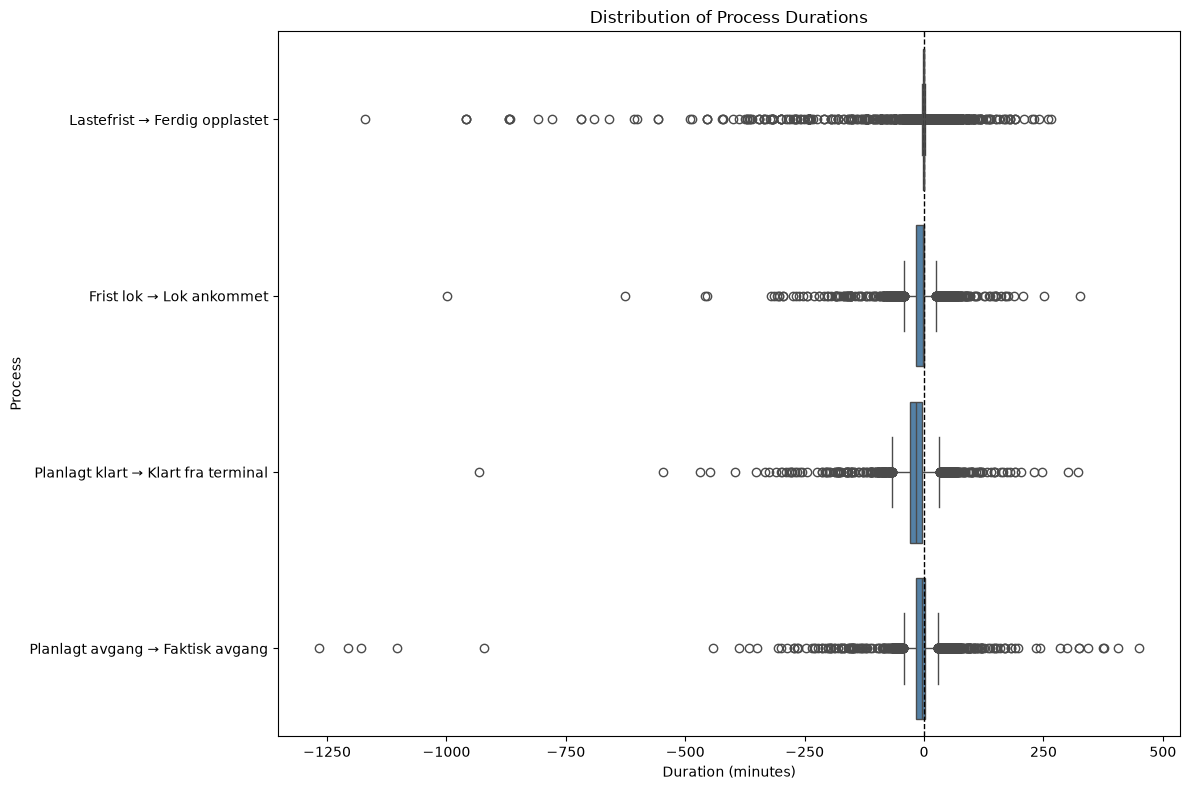

In [235]:
# Convert the duration columns to long format for plotting
process_duration_long = (
    df_outlier_check[process_duration_columns]
    .rename(columns={
        "Lastefrist to Ferdig opplastet (minutes)": (
            "Lastefrist → Ferdig opplastet"
        ),
        "Frist lok to Lok ankommet (minutes)": (
            "Frist lok → Lok ankommet"
        ),
        "Planlagt klart to Klart fra terminal (minutes)": (
            "Planlagt klart → Klart fra terminal"
        ),
        "Planlagt avgang to Faktisk avgang (minutes)": (
            "Planlagt avgang → Faktisk avgang"
        ),
    })
    .melt(
        var_name="Process",
        value_name="Duration (minutes)",
    )
    .dropna(subset=["Duration (minutes)"])
)

plt.figure(figsize=(12, 8))

sns.boxplot(
    data=process_duration_long,
    x="Duration (minutes)",
    y="Process",
    color="steelblue",
    showfliers=True,
)

plt.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1,
)

plt.title("Distribution of Process Durations")
plt.xlabel("Duration (minutes)")
plt.ylabel("Process")
plt.tight_layout()
plt.show()

In [236]:
# Aggregate the number of boxplot outliers for each process

def calculate_process_summary(values):
    values = values.dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = (
        (values < lower_bound)
        | (values > upper_bound)
    ).sum()

    return pd.Series({
        "number_of_observations": len(values),
        "number_of_outliers": outlier_count,
        "outlier_percentage": (
            outlier_count / len(values) * 100
        ),
    })


outlier_summary_by_process = (
    process_duration_long
    .groupby("Process")["Duration (minutes)"]
    .apply(calculate_process_summary)
    .unstack()
    .reset_index()
)

outlier_summary_by_process["outlier_percentage"] = (
    outlier_summary_by_process["outlier_percentage"]
    .round(2)
)

outlier_summary_by_process

,Process,number_of_observations,number_of_outliers,outlier_percentage
0,Frist lok → Lok ankommet,4390.0,525.0,11.96
1,Lastefrist → Ferdig opplastet,4390.0,1763.0,40.16
2,Planlagt avgang → Faktisk avgang,4390.0,526.0,11.98
3,Planlagt klart → Klart fra terminal,4390.0,311.0,7.08


*Note:* These calculations does not account for *overnight* departures, which is the next topic to explore.

*Definition of overnight departure, here:* When a train is prepared one day, but leaves after midnight, i.e. the next day.

*Underlying issue:* We do not know if `Avgangsdato` is related to the preparation day, or the actual departure date, for overnight departures

In [237]:
# Identify possible overnight departures by comparing "later" lastefrist to early departure
df_overnight_check = df_terminallogg_clean.copy()

lastefrist = pd.to_timedelta(
    df_overnight_check["Lastefrist"],
    errors="coerce",
)

planned_departure = pd.to_timedelta(
    df_overnight_check["Planlagt avgang"],
    errors="coerce",
)

actual_departure = pd.to_timedelta(
    df_overnight_check["Faktisk avgang"],
    errors="coerce",
)

possible_overnight = (
    lastefrist.notna()
    & planned_departure.notna()
    & actual_departure.notna()
    & (lastefrist > planned_departure)
    & (lastefrist > actual_departure)
)

df_possible_overnight = (
    df_overnight_check.loc[possible_overnight]
    .copy()
    .reset_index(drop=True)
)

print(
    "Possible overnight departures:",
    len(df_possible_overnight),
)

df_possible_overnight[
    [
        "LoggTogID",
        "Avgangsdato",
        "Tognummer",
        "Lastefrist",
        "Planlagt avgang",
        "Faktisk avgang",
    ]
]

Possible overnight departures: 292


,LoggTogID,Avgangsdato,Tognummer,Lastefrist,Planlagt avgang,Faktisk avgang
0,03-08-2025_5711,2025-08-03,5711.0,12:00:00,08:12:00,07:19:00
1,18-08-2025_5301,2025-08-18,5301.0,19:30:00,08:51:00,07:51:00
2,01-09-2025_5301,2025-09-01,5301.0,19:30:00,08:51:00,09:20:00
3,08-09-2025_5301,2025-09-08,5301.0,19:30:00,08:51:00,08:49:00
4,15-09-2025_5301,2025-09-15,5301.0,19:30:00,08:51:00,08:58:00
...,...,...,...,...,...,...
287,09-09-2026_5301,2026-09-09,5301.0,19:30:00,08:51:00,08:55:00
288,10-09-2026_5301,2026-09-10,5301.0,19:30:00,08:51:00,09:43:00
289,11-09-2026_5301,2026-09-11,5301.0,19:30:00,08:51:00,08:50:00
290,13-09-2026_5711,2026-09-13,5711.0,14:30:00,08:07:00,07:26:00


In [238]:
lastefrist_after_planned = (
    lastefrist.notna()
    & planned_departure.notna()
    & (lastefrist > planned_departure)
)

lastefrist_after_actual = (
    lastefrist.notna()
    & actual_departure.notna()
    & (lastefrist > actual_departure)
)

print(
    "Lastefrist later than planned departure:",
    lastefrist_after_planned.sum(),
)

print(
    "Lastefrist later than actual departure:",
    lastefrist_after_actual.sum(),
)

print(
    "Lastefrist later than both planned and actual departure:",
    possible_overnight.sum(),
)

Lastefrist later than planned departure: 319
Lastefrist later than actual departure: 387
Lastefrist later than both planned and actual departure: 292


In [239]:
# Inspecting the records where Lastefrist is at a later timestamp than either planned or actual departure
lastefrist_after_either_departure = (
    lastefrist_after_planned
    | lastefrist_after_actual
)

df_lastefrist_after_departure = (
    df_overnight_check.loc[
        lastefrist_after_either_departure
    ]
    .copy()
    .reset_index(drop=True)
)

df_lastefrist_after_departure[
    [
        "LoggTogID",
        "Avgangsdato",
        "Tognummer",
        "Lastefrist",
        "Planlagt avgang",
        "Faktisk avgang",
    ]
]

,LoggTogID,Avgangsdato,Tognummer,Lastefrist,Planlagt avgang,Faktisk avgang
0,03-08-2025_5711,2025-08-03,5711.0,12:00:00,08:12:00,07:19:00
1,11-08-2025_5301,2025-08-11,5301.0,19:30:00,08:51:00,<NA>
2,12-08-2025_5301,2025-08-12,5301.0,08:11:00,08:51:00,07:49:00
3,12-08-2025_5707,2025-08-12,5707.0,16:32:00,17:12:00,16:28:00
4,14-08-2025_5301,2025-08-14,5301.0,08:11:00,08:51:00,07:54:00
...,...,...,...,...,...,...
409,13-09-2026_5711,2026-09-13,5711.0,14:30:00,08:07:00,07:26:00
410,14-09-2026_5531,2026-09-14,5531.0,07:50:00,08:23:00,07:41:00
411,14-09-2026_5301,2026-09-14,5301.0,19:30:00,08:51:00,09:10:00
412,15-09-2026_5301,2026-09-15,5301.0,19:30:00,08:51:00,<NA>


In [240]:
overnight_time_pairs = (
    df_lastefrist_after_departure[
        [
            "Lastefrist",
            "Planlagt avgang",
            "Faktisk avgang",
            "Tognummer"
        ]
    ]
    .value_counts()
    .reset_index(name="number_of_rows")
)

overnight_time_pairs.head(20)

,Lastefrist,Planlagt avgang,Faktisk avgang,Tognummer,number_of_rows
0,19:30:00,08:51:00,08:51:00,5301.0,45
1,19:30:00,08:51:00,08:50:00,5301.0,17
2,19:30:00,08:51:00,08:56:00,5301.0,10
3,19:30:00,08:51:00,08:49:00,5301.0,9
4,19:30:00,08:51:00,08:48:00,5301.0,7
5,19:30:00,08:51:00,08:41:00,5301.0,7
6,19:30:00,08:51:00,08:53:00,5301.0,6
7,19:30:00,08:51:00,08:54:00,5301.0,6
8,19:30:00,08:51:00,08:43:00,5301.0,5
9,19:30:00,08:51:00,08:55:00,5301.0,5


*Comment:* Overnight departures look to be occuring in practice for a little more than 400 train departures, and that manye of these relates to the `5301` train. This could be analyzed further.

In [241]:
possible_overnight_by_train = (
    df_lastefrist_after_departure
    .groupby("Tognummer")
    .agg(
        number_of_log_rows=("Tognummer", "size"),
        number_of_dates=("Avgangsdato", "nunique"),
        earliest_lastefrist=("Lastefrist", "min"),
        latest_lastefrist=("Lastefrist", "max"),
        earliest_planned_departure=("Planlagt avgang", "min"),
        latest_planned_departure=("Planlagt avgang", "max"),
        earliest_actual_departure=("Faktisk avgang", "min"),
        latest_actual_departure=("Faktisk avgang", "max"),
    )
    .sort_values(
        "number_of_log_rows",
        ascending=False,
    )
)

possible_overnight_by_train.head(20)

,number_of_log_rows,number_of_dates,earliest_lastefrist,latest_lastefrist,earliest_planned_departure,latest_planned_departure,earliest_actual_departure,latest_actual_departure
Tognummer,,,,,,,,
5301.0,233,233,08:11:00,19:30:00,08:30:00,08:51:00,07:44:00,10:50:00
5711.0,47,47,12:00:00,14:30:00,07:30:00,08:40:00,07:06:00,08:20:00
41910.0,16,16,17:35:00,17:45:00,10:14:00,18:34:00,00:10:00,17:43:00
41971.0,14,14,13:30:00,17:18:00,17:44:00,17:58:00,10:23:00,17:13:00
41900.0,11,11,19:40:00,19:46:00,14:20:00,20:34:00,00:55:00,20:49:00
5709.0,11,11,20:20:00,21:00:00,21:12:00,21:51:00,00:24:00,20:57:00
41960.0,10,10,13:30:00,21:17:00,08:37:00,21:57:00,02:07:00,21:01:00
5703.0,8,8,22:00:00,22:00:00,01:55:00,02:35:00,01:30:00,02:58:00
5735.0,8,8,21:50:00,22:02:00,22:42:00,22:42:00,00:24:00,21:47:00


In [242]:
planned_minutes = (
    pd.to_timedelta(
        df_overnight_check["Planlagt avgang"],
        errors="coerce",
    )
    .dt.total_seconds()
    / 60
)

actual_minutes = (
    pd.to_timedelta(
        df_overnight_check["Faktisk avgang"],
        errors="coerce",
    )
    .dt.total_seconds()
    / 60
)

possible_overnight_departure = (
    actual_minutes < 6 * 60
) & (
    planned_minutes >= 6 * 60
)

df_possible_overnight_departure = (
    df_overnight_check.loc[
        possible_overnight_departure
    ]
    .copy()
    .sort_values(
        ["Tognummer", "Avgangsdato"]
    )
)

print(
    "Possible overnight departure cases purely because of delays:",
    len(df_possible_overnight_departure),
)

df_possible_overnight_departure[
    [
        "LoggTogID",
        "Avgangsdato",
        "Tognummer",
        "Lastefrist",
        "Planlagt avgang",
        "Faktisk avgang",
    ]
]

Possible overnight departure cases purely because of delays: 14


,LoggTogID,Avgangsdato,Tognummer,Lastefrist,Planlagt avgang,Faktisk avgang
1697,22-12-2025_5515,2025-12-22,5515.0,21:15:00,21:57:00,02:57:00
2130,15-01-2026_5515,2026-01-15,5515.0,21:15:00,21:57:00,00:30:00
2653,24-02-2026_5515,2026-02-24,5515.0,21:15:00,21:57:00,00:28:00
3774,20-05-2026_5515,2026-05-20,5515.0,21:15:00,21:57:00,00:04:00
1695,22-12-2025_5709,2025-12-22,5709.0,21:00:00,21:42:00,02:40:00
4454,15-07-2026_5709,2026-07-15,5709.0,21:00:00,21:51:00,01:44:00
4467,16-07-2026_5709,2026-07-16,5709.0,21:00:00,21:51:00,00:24:00
1698,22-12-2025_5735,2025-12-22,5735.0,21:50:00,22:42:00,03:30:00
2131,15-01-2026_5735,2026-01-15,5735.0,21:50:00,22:42:00,00:24:00
4456,15-07-2026_5735,2026-07-15,5735.0,21:50:00,22:42:00,01:35:00


*Comment:* The planned overnight departures are highly related to train **5301**, although not all. There also looks to be at least 14 overnight departures which were not planned, indicating delays might create overnight departures as well.

Handling such overnight departures, no matter the reason for actual departure time, might although be complicated, and a thorough process analysis might have to exclude such records to simplify analysis. If so, this would be a limitation of the analysis. Such overnight departures should however be *included* for general root cause analysis of the delay reason codes.

##### Data types/formats

In [243]:
# Check data types (of cleaned dataset)
df_terminallogg_clean.dtypes

Merknad                                       str
Tognummer                                 float64
Avgangsdato                        datetime64[us]
Lastefrist                                 string
Ferdig opplastet                           string
Frist lok                                  string
Lok ankommet                               string
Planlagt klart fra terminal                string
Klart fra terminal                         string
Planlagt avgang                            string
Faktisk avgang                             string
Årsakskode - avgangsforsinkelse               str
Kommentar                                     str
LoggTogID                                     str
dtype: object

*Comment:* The selected columns mostly have suitable data types and formats for further analysis. However, `Tognummer` is an ID and should be str instead of float64. String and str are generally the same, although string might be better suited for better pandas functions. Looking at how well this format has been functioning as a basis for further timestamps comparisons (related to overnight departures), this might influence the choice of timestamp formatting of the other datasets as well.

### Summary and final verdict of this dataset

The combined dataset covers **1 August 2025 to 16 September 2026** and initially contains **6,065 records**. After excluding **816 cancelled departures**, removing incomplete duplicate records, and deleting rows without `Tognummer` or `LoggTogID`, **5,227 departure records remain**. The final grain is valid: **one unique row per departure**.

The main data-quality issue is incomplete process information. **830 records (15.81%)** are missing at least one process timestamp. After also accounting for invalid timestamp formats, **4,393 records (83.69%)** contain all eight required timestamps in an accepted format and can be used for complete-case process-time analysis. The remaining records can still be used for analyses involving only the timestamps they contain.

The timestamps were inconsistently formatted, especially because some used `HH:MM` rather than `HH:MM:SS`. These values were normalized, while uncertain decimal time values were treated as missing. Only a small number of non-missing values still have invalid formats.

Process-time outlier analysis found the highest proportion of outliers for `Lastefrist → Ferdig opplastet` (**40.16%**). This likely reflects the operational meaning of `Lastefrist` as a deadline, as well as tighter distributions and possible midnight-crossing effects, rather than simple data-entry errors. The other process measures had between **7.08% and 11.98%** outliers.

Possible overnight departures were also identified. The pattern is strongly concentrated around train **5301**, where an evening loading deadline is repeatedly associated with a morning departure. This likely reflects an operational scheduling convention. However, because the timestamps contain time of day but not complete dates, overnight records cannot be classified with certainty and should not be automatically date-adjusted.

**Final verdict:** The cleaned Terminallogg dataset is suitable for departure-level analysis and is the most useful source for analysing terminal processes and departure performance. It is also suitable for process-time analysis, but the analysis should primarily use the **4,393 complete and correctly formatted records**, while documenting missing timestamps, remaining format issues, and uncertainty around overnight departures. `Tognummer` should be converted from `float64` to a string identifier before final analysis.

## Combined dataset: one-big-table

##### Thoughts before moving on:
What data should initially be removed from each datasets before combining them?
- Arrival only records
- Departures outside of the analysis period
- Cancelled trains
- Trains "just passing through" Alnabru
- Other planned, but not departed trains
- Duplicate rows (remove just one of the instances)
- Rows w/ duplicate `LoggTogID`s (remove just one of the instances)
- Empty rows
- Rows w/ missing `Tognummer` (train ID) or `LoggTogID`

What data should be kept?
- Actual departures during the analysis period
- Rows even w/o complete timestamps in the terminal logs (Can later be removed for a specified subset)
- Overnight departures (Can later be removed for a specified subset)

Resulting grain:
- One row per `LoggTogID`, representing one row/record per departure

How should the data be formatted (in general):
- IDs: str
- Dates: datetime64[us] (YYYY-MM-DD) + a column with the "visual" representation (DD-MM-YYYY)
- Timestamps: string (HH:MM:SS) adjusted to correct timezone (Europe/Oslo), should represent time-of-day (thus being date independent)
- Delay amount: int64 (minutes), should be nullable
- Delay codes, comments and categorical columns: str

### Summary of things needed to be handled in each table (a list)

The following table summarizes the measures to be implemented (or not) based on the findings of the individual data quality analysises:

| Dataset | Remove or exclude before combining | Keep or transform | Do not remove automatically / document | Role after preparation |
|---|---|---|---|---|
| **Vy operating train routes** (`bronze_tp_operating_train_routes_ALB`) | - Arrival-only records<br>- Cancelled trains<br>- Trains marked as just passing through Alnabru<br>- Departures outside the analysis period<br>- Planned trains without an actual departure<br>- Rows without `Tognummer` or `LoggTogID`<br>- Empty rows<br>- Exact duplicate rows<br>- One instance of duplicate `LoggTogID` rows, after checking the records | - Keep actual departures during the analysis period<br>- Construct and validate `LoggTogID`<br>- Convert IDs to `str`<br>- Convert dates to `datetime64[us]` and optionally add a visual `DD-MM-YYYY` column<br>- Store timestamps as date-independent `HH:MM:SS` strings adjusted to `Europe/Oslo`<br>- Convert departure delays to nullable `Int64` minutes | - The 151 rows with a scheduled departure but no actual departure should be excluded from the actual-departure table<br>- Delay outliers should be investigated, not removed automatically | Main source for the population of actual departures and departure-performance variables |
| **TIOS delayed-train report** (`ExcelReport-6f2dcb04-d1bc-4d7e-b997-cbd3a93fe1b3`) | - Exact duplicate rows<br>- Rows outside the analysis period<br>- Empty rows<br>- Rows without required identifiers, if found during final preparation<br>- Cancelled records, if any are found during final preparation | - Keep registered delay records within the analysis period<br>- Keep `Dato`, `Tognr`, `Forsinkelse`, `Årsak`, `Kommentar` and `LoggTogID`<br>- Convert IDs to `str`<br>- Convert `Forsinkelse` from `hh:mm` to nullable `Int64` minutes<br>- Convert `Årsak` to `str`<br>- Keep explanatory fields as nullable strings | - This dataset contains delayed trains only and is not a complete overview of departures<br>- Missing `HL-beskrivelse` and `Kommentar` should remain missing<br>- Delay outliers should be investigated, not removed automatically<br>- Verify `LoggTogID` uniqueness before joining | Source for registered delay events and delay-cause information |
| **Cause-code list** (`Årsakskodelister`) | - No rows based on the current analysis<br>- Do not remove the row with the missing performance-category mapping | - Keep all reason-code records<br>- Store codes, descriptions, and categories as strings<br>- Use as a lookup table for delay and terminal-log records | - Keep this as a separate reference table<br>- Validate that all delay codes in the operational datasets are mapped or explicitly reported as unmapped | Reference table for enriching delay and terminal-log records |
| **Terminal logs: R25 and R26** | - Cancelled departures<br>- Rows without `Tognummer` or `LoggTogID`<br>- Empty rows<br>- Incomplete duplicate records<br>- One instance of duplicate `LoggTogID` rows, after checking the records<br>- Rows outside the analysis period | - Combine R25 and R26 after aligning column names and data types<br>- Keep actual departures during the analysis period<br>- Keep records with incomplete terminal timestamps<br>- Keep overnight departures<br>- Convert IDs to `str`<br>- Convert dates to `datetime64[us]` and optionally add a visual `DD-MM-YYYY` column<br>- Store timestamps as date-independent `HH:MM:SS` strings adjusted to `Europe/Oslo`<br>- Convert delay amounts to nullable `Int64` minutes<br>- Store delay codes, comments, and categorical fields as strings | - Do not remove records merely because one or more terminal timestamps are missing<br>- Do not automatically remove possible overnight departures<br>- Do not automatically remove process-time outliers<br>- Use complete-case subsets when calculating process durations requiring all timestamps<br>- Do not automatically date-adjust possible overnight records | Main source for terminal-process measures and terminal departure performance |

### Import and preparation of each dataset

In [1]:
# Imports
import re
import pandas as pd

# Configuration
start_date = pd.Timestamp("2025-08-01")
end_date = pd.Timestamp("2026-09-16")

#### Terminallogg R25 and R26

##### Import and transformation

In [2]:
# ---------------------------------------------------------------------
# Configuration
# ---------------------------------------------------------------------

time_columns = [
    "Lastefrist",
    "Ferdig opplastet",
    "Frist lok",
    "Lok ankommet",
    "Planlagt klart fra terminal",
    "Klart fra terminal",
    "Planlagt avgang",
    "Faktisk avgang",
]

relevant_columns = [
    "Merknad",
    "Tognummer",
    "Avgangsdato",
    *time_columns,
    "Årsakskode - avgangsforsinkelse",
    "Kommentar",
    "LoggTogID",
]

cancellation_code = "T17 - Innstilt tog"


# ---------------------------------------------------------------------
# Helper functions
# ---------------------------------------------------------------------

def normalize_identifier(series):
    """
    Convert an identifier to pandas nullable string format.

    Numeric values imported as 123.0 are converted to "123".
    Empty strings are converted to <NA>.
    """
    values = series.astype("string").str.strip()
    values = values.mask(values.eq(""))

    values = values.str.replace(
        r"^(\d+)\.0$",
        r"\1",
        regex=True,
    )

    return values


def normalize_time_of_day(series):
    """
    Convert values to date-independent HH:MM:SS strings.

    HH:MM is converted to HH:MM:SS.
    Fractional seconds are removed.
    Empty, decimal-style, and invalid values become <NA>.
    """
    values = series.astype("string").str.strip()
    values = values.mask(values.eq(""))

    # Remove fractional seconds from valid HH:MM:SS values.
    values = values.str.replace(
        r"^((?:[01]\d|2[0-3]):[0-5]\d:[0-5]\d)\.\d+$",
        r"\1",
        regex=True,
    )

    # Convert valid HH:MM values to HH:MM:SS.
    hh_mm_mask = values.str.fullmatch(
        r"(?:[01]\d|2[0-3]):[0-5]\d"
    )

    values = values.mask(
        hh_mm_mask,
        values.loc[hh_mm_mask] + ":00",
    )

    # Keep only valid HH:MM:SS values.
    valid_hh_mm_ss_mask = values.str.fullmatch(
        r"(?:[01]\d|2[0-3]):[0-5]\d:[0-5]\d"
    )

    values = values.where(valid_hh_mm_ss_mask)

    return values.astype("string")



# ---------------------------------------------------------------------
# Import R25 and R26
# ---------------------------------------------------------------------

df_terminallogg_r25 = pd.read_csv(
    "../data/Terminallogg R25.csv",
    sep=";",
    encoding="utf-8-sig",
)

df_terminallogg_r26 = pd.read_csv(
    "../data/Terminallogg R26.csv",
    sep=";",
    encoding="utf-8-sig",
)


# Remove accidental whitespace from column names.
df_terminallogg_r25.columns = (
    df_terminallogg_r25.columns
    .astype("string")
    .str.strip()
)

df_terminallogg_r26.columns = (
    df_terminallogg_r26.columns
    .astype("string")
    .str.strip()
)


# ---------------------------------------------------------------------
# Convert Avgangsdato before combining R25 and R26
# ---------------------------------------------------------------------

# Use dt.normalize() as well to set the time component of the Avgangsdato to 00:00
df_terminallogg_r25["Avgangsdato"] = pd.to_datetime(
    df_terminallogg_r25["Avgangsdato"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce",
)

df_terminallogg_r26["Avgangsdato"] = pd.to_datetime(
    df_terminallogg_r26["Avgangsdato"],
    format="%Y-%m-%d",
    errors="coerce",
)


# ---------------------------------------------------------------------
# Combine R25 and R26
# ---------------------------------------------------------------------

df_terminallogg = pd.concat(
    [
        df_terminallogg_r25,
        df_terminallogg_r26,
    ],
    ignore_index=True,
)


# ---------------------------------------------------------------------
# Filter to the analysis period
# ---------------------------------------------------------------------

df_terminallogg_filtered = (
    df_terminallogg[
        df_terminallogg["Avgangsdato"].between(
            start_date,
            end_date,
            inclusive="both"
        )
    ]
    .copy()
    .reset_index(drop=True)
)


# ---------------------------------------------------------------------
# Convert Tognummer and LoggTogID to string
# ---------------------------------------------------------------------

df_terminallogg_filtered["Tognummer"] = normalize_identifier(
    df_terminallogg_filtered["Tognummer"]
)

df_terminallogg_filtered["LoggTogID"] = normalize_identifier(
    df_terminallogg_filtered["LoggTogID"]
)


# ---------------------------------------------------------------------
# Select relevant columns
# ---------------------------------------------------------------------

df_terminallogg_filtered = (
    df_terminallogg_filtered[relevant_columns]
    .copy()
)


# ---------------------------------------------------------------------
# Remove cancelled trains
# ---------------------------------------------------------------------

cancelled_mask = (
    df_terminallogg_filtered[
        "Årsakskode - avgangsforsinkelse"
    ]
    .astype("string")
    .str.strip()
    .eq(cancellation_code)
)

df_terminallogg_cancelled = (df_terminallogg_filtered[
    df_terminallogg_filtered["Årsakskode - avgangsforsinkelse"] == "T17 - Innstilt tog"
    ]).copy()

df_terminallogg_filtered= (
    df_terminallogg_filtered[
        df_terminallogg_filtered["Årsakskode - avgangsforsinkelse"]
        != "T17 - Innstilt tog"
    ]
    .copy()
    .reset_index(drop=True)
)


# ---------------------------------------------------------------------
# Remove exact duplicate rows
# ---------------------------------------------------------------------

exact_duplicate_mask = (
    df_terminallogg_filtered
    .duplicated(keep="first")
)

df_terminallogg_exact_duplicates = (
    df_terminallogg_filtered.loc[exact_duplicate_mask]
    .copy()
)

df_terminallogg_filtered = (
    df_terminallogg_filtered.loc[~exact_duplicate_mask]
    .copy()
    .reset_index(drop=True)
)


# ---------------------------------------------------------------------
# Remove empty rows
# ---------------------------------------------------------------------

empty_row_mask = (
    df_terminallogg_filtered
    .replace(r"^\s*$", pd.NA, regex=True)
    .isna()
    .all(axis=1)
)

df_terminallogg_empty_rows = (
    df_terminallogg_filtered.loc[empty_row_mask]
    .copy()
)

df_terminallogg_filtered = (
    df_terminallogg_filtered.loc[~empty_row_mask]
    .copy()
    .reset_index(drop=True)
)


# ---------------------------------------------------------------------
# Remove rows missing Tognummer or LoggTogID
# ---------------------------------------------------------------------

missing_id_mask = (
    df_terminallogg_filtered["Tognummer"].isna()
    | df_terminallogg_filtered["LoggTogID"].isna()
)

df_terminallogg_missing_ids = (
    df_terminallogg_filtered.loc[missing_id_mask]
    .copy()
)

df_terminallogg_filtered = (
    df_terminallogg_filtered.loc[~missing_id_mask]
    .copy()
    .reset_index(drop=True)
)


# ---------------------------------------------------------------------
# Convert timestamps to date-independent HH:MM:SS strings
# ---------------------------------------------------------------------

for column in time_columns:
    df_terminallogg_filtered[column] = normalize_time_of_day(
        df_terminallogg_filtered[column]
    )

invalid_time_summary = {}

for column in time_columns:
    values = df_terminallogg_filtered[column].astype("string")

    valid_time_format = values.str.fullmatch(
        r"(?:[01]\d|2[0-3]):[0-5]\d:[0-5]\d"
    )

    invalid_time_summary[column] = int(
        (values.notna() & ~valid_time_format).sum()
    )

invalid_time_summary = pd.Series(
    invalid_time_summary,
    name="invalid_non_missing_values",
)

print("Invalid time formats after conversion:")
display(invalid_time_summary)

assert invalid_time_summary.sum() == 0


Invalid time formats after conversion:


Lastefrist                     0
Ferdig opplastet               0
Frist lok                      0
Lok ankommet                   0
Planlagt klart fra terminal    0
Klart fra terminal             0
Planlagt avgang                0
Faktisk avgang                 0
Name: invalid_non_missing_values, dtype: int64

In [3]:
# ---------------------------------------------------------------------
# Check duplicate LoggTogID values for manual review
# ---------------------------------------------------------------------

duplicate_logg_tog_id_mask = (
    df_terminallogg_filtered["LoggTogID"]
    .duplicated(keep=False)
)

df_terminallogg_duplicate_logg_tog_ids = (
    df_terminallogg_filtered.loc[
        duplicate_logg_tog_id_mask
    ]
    .sort_values("LoggTogID")
    .copy()
)

print(
    "Rows with duplicated LoggTogID values:",
    len(df_terminallogg_duplicate_logg_tog_ids),
)

print(
    "Duplicated LoggTogID groups:",
    df_terminallogg_duplicate_logg_tog_ids["LoggTogID"].nunique(),
)

display(df_terminallogg_duplicate_logg_tog_ids)

Rows with duplicated LoggTogID values: 6
Duplicated LoggTogID groups: 3


,Merknad,Tognummer,Avgangsdato,Lastefrist,Ferdig opplastet,Frist lok,Lok ankommet,Planlagt klart fra terminal,Klart fra terminal,Planlagt avgang,Faktisk avgang,Årsakskode - avgangsforsinkelse,Kommentar,LoggTogID
3993,LANGTOG,5515,2026-06-08,21:15:00,<NA>,21:17:00,<NA>,21:52:00,<NA>,21:57:00,<NA>,NaN,NaN,08-06-2026_5515
3994,LANGTOG,5515,2026-06-08,21:15:00,21:15:00,21:17:00,21:17:00,21:52:00,21:40:00,21:57:00,21:54:00,NaN,NaN,08-06-2026_5515
74,NaN,5507,2025-08-08,<NA>,<NA>,11:43:00,<NA>,12:18:00,<NA>,12:23:00,<NA>,T1 - I rute,NaN,08-08-2025_5507
79,NaN,5507,2025-08-08,<NA>,11:40:00,11:36:00,11:36:00,12:11:00,12:02:00,12:16:00,12:15:00,NaN,NaN,08-08-2025_5507
5126,NaN,85511,2026-09-09,16:45:00,16:45:00,16:51:00,16:50:00,17:26:00,17:04:00,17:31:00,17:36:00,"T34 - Annen feil, forklaring i kommentarfelt",Uvvist årsak,09-09-2026_85511
5131,LANGTOG,85511,2026-09-09,20:00:00,<NA>,16:51:00,<NA>,17:26:00,17:10:00,17:31:00,17:20:00,NaN,NaN,09-09-2026_85511


In [30]:
# Remove the manually identified duplicate rows.
rows_to_remove = [3993, 74, 5131]

df_terminallogg_clean = (
    df_terminallogg_filtered
    .drop(index=rows_to_remove)
    .reset_index(drop=True)
)

# Verify that the selected rows were removed.
print("Removed rows:", rows_to_remove)
print("Rows after manual duplicate removal:", len(df_terminallogg_clean))

# Verify that no duplicate LoggTogID values remain.
duplicate_logg_tog_ids_remaining = (
    df_terminallogg_clean["LoggTogID"]
    .duplicated()
    .sum()
)

print(
    "Duplicate LoggTogID values remaining:",
    duplicate_logg_tog_ids_remaining,
)

# Cell 161 checks.
print("Rows after cleaning:", len(df_terminallogg_clean))
print(
    "Missing LoggTogID values:",
    df_terminallogg_clean["LoggTogID"].isna().sum(),
)
print(
    "Missing Tognummer values:",
    df_terminallogg_clean["Tognummer"].isna().sum(),
)

# Final grain validation.
assert duplicate_logg_tog_ids_remaining == 0
assert df_terminallogg_clean["LoggTogID"].notna().all()
assert df_terminallogg_clean["Tognummer"].notna().all()
assert df_terminallogg_clean["LoggTogID"].is_unique

Removed rows: [3993, 74, 5131]
Rows after manual duplicate removal: 5227
Duplicate LoggTogID values remaining: 0
Rows after cleaning: 5227
Missing LoggTogID values: 0
Missing Tognummer values: 0


In [31]:
# ---------------------------------------------------------------------
# Rename columns to make them more informative for combination with the other datasets
# ---------------------------------------------------------------------

df_terminallogg_clean = df_terminallogg_clean.rename(
    columns={
        "Årsakskode - avgangsforsinkelse": "Årsakskode - terminal",
        "Kommentar": "Kommentar - terminal",
        "Planlagt avgang": "Planlagt avgangstid - terminal",
        "Faktisk avgang": "Faktisk avgangstid - terminal"
    }
)

##### Verification of correct transformations

In [32]:
# Final verification of the cleaned terminal-log dataset

df = df_terminallogg_clean.copy()

time_columns = [
    "Lastefrist",
    "Ferdig opplastet",
    "Frist lok",
    "Lok ankommet",
    "Planlagt klart fra terminal",
    "Klart fra terminal",
    "Planlagt avgangstid - terminal",
    "Faktisk avgangstid - terminal",
]

relevant_columns_renamed = [
    "Merknad",
    "Tognummer",
    "Avgangsdato",
    *time_columns,
    "Årsakskode - terminal",
    "Kommentar - terminal",
    "LoggTogID",
]

# ---------------------------------------------------------------------
# 1. Row and column structure
# ---------------------------------------------------------------------

print("Final dimensions:", df.shape)
print("Columns:")
print(df.columns.tolist())

assert len(df) > 0
assert set(relevant_columns_renamed).issubset(df.columns)


# ---------------------------------------------------------------------
# 2. Analysis-period verification
# ---------------------------------------------------------------------

assert df["Avgangsdato"].notna().all()

assert df["Avgangsdato"].between(
    start_date,
    end_date,
    inclusive="both",
).all()

print(
    "Date range:",
    df["Avgangsdato"].min().strftime("%Y-%m-%d"),
    "to",
    df["Avgangsdato"].max().strftime("%Y-%m-%d"),
)


# ---------------------------------------------------------------------
# 3. Identifier verification
# ---------------------------------------------------------------------

assert df["Tognummer"].notna().all()
assert df["LoggTogID"].notna().all()

assert df["Tognummer"].astype("string").str.strip().ne("").all()
assert df["LoggTogID"].astype("string").str.strip().ne("").all()

assert df["LoggTogID"].is_unique

print("Missing Tognummer values:", df["Tognummer"].isna().sum())
print("Missing LoggTogID values:", df["LoggTogID"].isna().sum())
print("Duplicate LoggTogID values:", df["LoggTogID"].duplicated().sum())


# ---------------------------------------------------------------------
# 4. Cancellation verification
# ---------------------------------------------------------------------

cancelled_rows_remaining = (
    df["Årsakskode - terminal"]
    .astype("string")
    .str.strip()
    .eq(cancellation_code)
    .sum()
)

assert cancelled_rows_remaining == 0

print("Cancelled rows remaining:", cancelled_rows_remaining)


# ---------------------------------------------------------------------
# 5. Duplicate and empty-row verification
# ---------------------------------------------------------------------

exact_duplicate_rows_remaining = df.duplicated().sum()

empty_rows_remaining = (
    df.replace(r"^\s*$", pd.NA, regex=True)
    .isna()
    .all(axis=1)
    .sum()
)

assert exact_duplicate_rows_remaining == 0
assert empty_rows_remaining == 0

print("Exact duplicate rows remaining:", exact_duplicate_rows_remaining)
print("Empty rows remaining:", empty_rows_remaining)


# ---------------------------------------------------------------------
# 6. Date-type verification
# ---------------------------------------------------------------------

assert pd.api.types.is_datetime64_any_dtype(
    df["Avgangsdato"]
)

print("Avgangsdato dtype:", df["Avgangsdato"].dtype)


# ---------------------------------------------------------------------
# 7. Timestamp-format verification
# ---------------------------------------------------------------------

timestamp_verification = {}

for column in time_columns:
    values = df[column].astype("string")

    valid_timestamp_mask = values.str.fullmatch(
        r"(?:[01]\d|2[0-3]):[0-5]\d:[0-5]\d"
    )

    invalid_non_missing = (
        values.notna()
        & ~valid_timestamp_mask
    )

    timestamp_verification[column] = int(
        invalid_non_missing.sum()
    )

timestamp_verification = pd.Series(
    timestamp_verification,
    name="invalid_non_missing_timestamps",
)

display(timestamp_verification)

assert timestamp_verification.sum() == 0


# ---------------------------------------------------------------------
# 8. Timestamp representation verification
# ---------------------------------------------------------------------

all_timestamp_values = (
    df[time_columns]
    .stack()
    .dropna()
    .astype("string")
)

contains_date_information = all_timestamp_values.str.contains(
    r"\d{4}-\d{2}-\d{2}",
    regex=True,
).any()

assert not contains_date_information


# ---------------------------------------------------------------------
# 9. Missing-value overview
# ---------------------------------------------------------------------

missing_value_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": (
        df.isna().mean() * 100
    ).round(2),
    "dtype": df.dtypes.astype("string"),
})

display(missing_value_summary)


# ---------------------------------------------------------------------
# 10. Final result
# ---------------------------------------------------------------------

print("Final verification completed successfully.")
print("Final row count:", len(df))
print("Final grain: one row per unique LoggTogID")

display(df.dtypes)

Final dimensions: (5227, 14)
Columns:
['Merknad', 'Tognummer', 'Avgangsdato', 'Lastefrist', 'Ferdig opplastet', 'Frist lok', 'Lok ankommet', 'Planlagt klart fra terminal', 'Klart fra terminal', 'Planlagt avgangstid - terminal', 'Faktisk avgangstid - terminal', 'Årsakskode - terminal', 'Kommentar - terminal', 'LoggTogID']
Date range: 2025-08-01 to 2026-09-16
Missing Tognummer values: 0
Missing LoggTogID values: 0
Duplicate LoggTogID values: 0
Cancelled rows remaining: 0
Exact duplicate rows remaining: 0
Empty rows remaining: 0
Avgangsdato dtype: datetime64[us]


Lastefrist                        0
Ferdig opplastet                  0
Frist lok                         0
Lok ankommet                      0
Planlagt klart fra terminal       0
Klart fra terminal                0
Planlagt avgangstid - terminal    0
Faktisk avgangstid - terminal     0
Name: invalid_non_missing_timestamps, dtype: int64

,missing_count,missing_percentage,dtype
Merknad,3036,58.08,str
Tognummer,0,0.00,string
Avgangsdato,0,0.00,datetime64[us]
Lastefrist,67,1.28,string
Ferdig opplastet,587,11.23,string
Frist lok,6,0.11,string
Lok ankommet,667,12.76,string
Planlagt klart fra terminal,7,0.13,string
Klart fra terminal,607,11.61,string
Planlagt avgangstid - terminal,8,0.15,string


Final verification completed successfully.
Final row count: 5227
Final grain: one row per unique LoggTogID


Merknad                                      str
Tognummer                                 string
Avgangsdato                       datetime64[us]
Lastefrist                                string
Ferdig opplastet                          string
Frist lok                                 string
Lok ankommet                              string
Planlagt klart fra terminal               string
Klart fra terminal                        string
Planlagt avgangstid - terminal            string
Faktisk avgangstid - terminal             string
Årsakskode - terminal                        str
Kommentar - terminal                         str
LoggTogID                                 string
dtype: object

#### Vy operating train routes

##### Import and transformation

In [33]:
# ---------------------------------------------------------------------
# Configuration
# ---------------------------------------------------------------------

time_columns_vy = [
    "scheduled_departure_time",
    "actual_departure_time",
    "actual_arrival_time",
    "estimated_arrival_time",
]

relevant_columns_vy = [
    "train_id",
    "train_date",
    "cancelled",
    "scheduled_departure_time",
    "actual_departure_time",
    "actual_arrival_time",
    "estimated_arrival_time",
    "just_passing_through",
    "departure_delay",
    "train_company",
    "LoggTogID",
]


# ---------------------------------------------------------------------
# Helper functions
# ---------------------------------------------------------------------

def normalize_identifier_vy(series):
    """
    Convert an identifier to pandas nullable string format.

    Numeric values imported as 123.0 are converted to "123".
    Empty strings are converted to <NA>.
    """
    values = series.astype("string").str.strip()
    values = values.mask(values.eq(""))

    values = values.str.replace(
        r"^(\d+)\.0$",
        r"\1",
        regex=True,
    )

    return values


def normalize_vy_timestamp(series):
    """
    Convert Vy timestamps to date-independent HH:MM:SS strings.

    Source timestamps are parsed as ISO timestamps. If timezone
    information is present, values are converted to Europe/Oslo
    before the date component is discarded.
    """
    values = series.astype("string").str.strip()
    values = values.mask(values.eq(""))

    parsed_values = pd.to_datetime(
        values,
        errors="coerce",
        utc=True,
    )

    # Convert timezone-aware values to Norwegian local time.
    parsed_values = parsed_values.dt.tz_convert("Europe/Oslo")

    return parsed_values.dt.strftime("%H:%M:%S").astype("string")


# ---------------------------------------------------------------------
# Import
# ---------------------------------------------------------------------

df_vy_alnabru_timings = pd.read_csv(
    "../data/bronze_tp_operating_train_routes_ALB.csv",
    sep=";",
    encoding="utf-8-sig",
)


# ---------------------------------------------------------------------
# Convert train date
# ---------------------------------------------------------------------

df_vy_alnabru_timings["train_date"] = pd.to_datetime(
    df_vy_alnabru_timings["train_date"],
    format="%Y-%m-%d",
    errors="coerce",
).dt.normalize()


# ---------------------------------------------------------------------
# Filter to the analysis period
# ---------------------------------------------------------------------

df_vy_timings_filtered = (
    df_vy_alnabru_timings[
        df_vy_alnabru_timings["train_date"].between(
            start_date,
            end_date,
            inclusive="both",
        )
    ]
    .copy()
    .reset_index(drop=True)
)


# ---------------------------------------------------------------------
# Convert train ID to string
# ---------------------------------------------------------------------

df_vy_timings_filtered["train_id"] = (
    normalize_identifier_vy(
        df_vy_timings_filtered["train_id"]
    )
)


# ---------------------------------------------------------------------
# Select the relevant columns before filtering
# ---------------------------------------------------------------------

relevant_columns_before_id = [
    column
    for column in relevant_columns_vy
    if column != "LoggTogID"
]

df_vy_timings_filtered = (
    df_vy_timings_filtered[relevant_columns_before_id]
    .copy()
)


# ---------------------------------------------------------------------
# Construct LoggTogID
# ---------------------------------------------------------------------

df_vy_timings_filtered["LoggTogID"] = (
    df_vy_timings_filtered["train_date"].dt.strftime("%d-%m-%Y")
    + "_"
    + df_vy_timings_filtered["train_id"]
)


# ---------------------------------------------------------------------
# Collect cancelled trains
# ---------------------------------------------------------------------

df_vy_cancelled_trains = (
    df_vy_timings_filtered[
        df_vy_timings_filtered["cancelled"]
        .astype("string")
        .str.strip()
        .eq("Y")
    ]
    .copy()
)


# ---------------------------------------------------------------------
# Remove cancelled trains
# ---------------------------------------------------------------------

cancelled_mask = (
    df_vy_timings_filtered["cancelled"] != "N"
)

df_vy_timings_filtered = (
    df_vy_timings_filtered[
        ~cancelled_mask
    ]
    .copy()
    .reset_index(drop=True)
)


# ---------------------------------------------------------------------
# Remove trains just passing through Alnabru
# ---------------------------------------------------------------------

passing_through_mask = (
    df_vy_timings_filtered["just_passing_through"]
    .fillna(False)
    .astype(bool)
)

df_vy_passing_through_trains = (
    df_vy_timings_filtered[
        passing_through_mask
    ]
    .copy()
)

df_vy_timings_filtered = (
    df_vy_timings_filtered[
        ~passing_through_mask
    ]
    .copy()
    .reset_index(drop=True)
)


# ---------------------------------------------------------------------
# Remove planned trains without an actual departure
# ---------------------------------------------------------------------

planned_without_actual_mask = (
    df_vy_timings_filtered["actual_departure_time"].isna()
)

df_vy_planned_without_actual = (
    df_vy_timings_filtered[
        planned_without_actual_mask
    ]
    .copy()
)

df_vy_timings_filtered = (
    df_vy_timings_filtered[
        ~planned_without_actual_mask
    ]
    .copy()
    .reset_index(drop=True)
)


# ---------------------------------------------------------------------
# Remove arrival-only records
# ---------------------------------------------------------------------

has_arrival_time = (
    df_vy_timings_filtered["actual_arrival_time"].notna()
    | df_vy_timings_filtered["estimated_arrival_time"].notna()
)

has_departure_time = (
    df_vy_timings_filtered["scheduled_departure_time"].notna()
    | df_vy_timings_filtered["actual_departure_time"].notna()
)

arrival_only_mask = has_arrival_time & ~has_departure_time

df_vy_arrival_only_trains = (
    df_vy_timings_filtered[
        arrival_only_mask
    ]
    .copy()
)

df_vy_timings_filtered = (
    df_vy_timings_filtered[
        ~arrival_only_mask
    ]
    .copy()
    .reset_index(drop=True)
)


# ---------------------------------------------------------------------
# Remove exact duplicate rows
# ---------------------------------------------------------------------

exact_duplicate_mask_vy = (
    df_vy_timings_filtered
    .duplicated(keep="first")
)

df_vy_exact_duplicates = (
    df_vy_timings_filtered[
        exact_duplicate_mask_vy
    ]
    .copy()
)

df_vy_timings_filtered = (
    df_vy_timings_filtered[
        ~exact_duplicate_mask_vy
    ]
    .copy()
    .reset_index(drop=True)
)


# ---------------------------------------------------------------------
# Remove empty rows
# ---------------------------------------------------------------------

empty_row_mask_vy = (
    df_vy_timings_filtered
    .replace(r"^\s*$", pd.NA, regex=True)
    .isna()
    .all(axis=1)
)

df_vy_empty_rows = (
    df_vy_timings_filtered[
        empty_row_mask_vy
    ]
    .copy()
)

df_vy_timings_filtered = (
    df_vy_timings_filtered[
        ~empty_row_mask_vy
    ]
    .copy()
    .reset_index(drop=True)
)


# ---------------------------------------------------------------------
# Remove rows missing train_id or LoggTogID
# ---------------------------------------------------------------------

missing_id_mask_vy = (
    df_vy_timings_filtered["train_id"].isna()
    | df_vy_timings_filtered["LoggTogID"].isna()
)

df_vy_missing_ids = (
    df_vy_timings_filtered[
        missing_id_mask_vy
    ]
    .copy()
)

df_vy_timings_filtered = (
    df_vy_timings_filtered[
        ~missing_id_mask_vy
    ]
    .copy()
    .reset_index(drop=True)
)


# ---------------------------------------------------------------------
# Convert departure delay to nullable integer minutes
# ---------------------------------------------------------------------

df_vy_timings_filtered["departure_delay"] = pd.to_numeric(
    df_vy_timings_filtered["departure_delay"],
    errors="coerce",
).astype("Int64")


# ---------------------------------------------------------------------
# Convert timestamps to date-independent HH:MM:SS strings
# ---------------------------------------------------------------------

for column in time_columns_vy:
    df_vy_timings_filtered[column] = normalize_vy_timestamp(
        df_vy_timings_filtered[column]
    )


# ---------------------------------------------------------------------
# Convert categorical columns to nullable strings
# ---------------------------------------------------------------------

string_columns_vy = [
    "cancelled",
    "just_passing_through",
    "train_company",
]

for column in string_columns_vy:
    df_vy_timings_filtered[column] = (
        df_vy_timings_filtered[column]
        .astype("string")
        .str.strip()
    )


# ---------------------------------------------------------------------
# Display duplicate LoggTogID rows for manual review
# ---------------------------------------------------------------------

duplicate_logg_tog_id_mask_vy = (
    df_vy_timings_filtered["LoggTogID"]
    .duplicated(keep=False)
)

df_vy_duplicate_logg_tog_ids = (
    df_vy_timings_filtered[
        duplicate_logg_tog_id_mask_vy
    ]
    .sort_values("LoggTogID")
    .copy()
)

print(
    "Rows with duplicated LoggTogID values:",
    len(df_vy_duplicate_logg_tog_ids),
)

print(
    "Duplicated LoggTogID groups:",
    df_vy_duplicate_logg_tog_ids["LoggTogID"].nunique(),
)

display(df_vy_duplicate_logg_tog_ids)

Rows with duplicated LoggTogID values: 0
Duplicated LoggTogID groups: 0


,train_id,train_date,cancelled,scheduled_departure_time,actual_departure_time,actual_arrival_time,estimated_arrival_time,just_passing_through,departure_delay,train_company,LoggTogID


In [34]:
df_vy_clean = df_vy_timings_filtered.copy()

In [35]:
# ---------------------------------------------------------------------
# Rename columns to make them more informative for combination with the other datasets
# ---------------------------------------------------------------------

df_vy_clean = df_vy_clean.rename(
    columns={
        "scheduled_departure_time": "Planlagt avgangstid - OTR",
        "actual_departure_time": "Faktisk avgangstid - OTR",
        "departure_delay": "Forsinkelse - OTR"
    }
)

##### Verification of correct transformations

In [36]:
# ---------------------------------------------------------------------
# Column names after renaming
# ---------------------------------------------------------------------

otr_scheduled_departure_column = (
    "Planlagt avgangstid - OTR"
)

otr_actual_departure_column = (
    "Faktisk avgangstid - OTR"
)

otr_delay_column = "Forsinkelse - OTR"

# ---------------------------------------------------------------------
# Verify row and column structure
# ---------------------------------------------------------------------

print("Final dimensions:", df_vy_clean.shape)
print("Columns:")
print(df_vy_clean.columns.tolist())

assert len(df_vy_clean) > 0
relevant_columns_vy_renamed = [
    "train_id",
    "train_date",
    "cancelled",
    "Planlagt avgangstid - OTR",
    "Faktisk avgangstid - OTR",
    "actual_arrival_time",
    "estimated_arrival_time",
    "just_passing_through",
    "Forsinkelse - OTR",
    "train_company",
    "LoggTogID",
]

assert set(relevant_columns_vy_renamed).issubset(
    df_vy_clean.columns
)


# ---------------------------------------------------------------------
# Verify analysis-period filtering
# ---------------------------------------------------------------------

assert df_vy_clean["train_date"].notna().all()

assert df_vy_clean["train_date"].between(
    start_date,
    end_date,
    inclusive="both",
).all()

print(
    "Date range:",
    df_vy_clean["train_date"].min().strftime("%Y-%m-%d"),
    "to",
    df_vy_clean["train_date"].max().strftime("%Y-%m-%d"),
)


# ---------------------------------------------------------------------
# Verify actual departures
# ---------------------------------------------------------------------

assert df_vy_clean[
    otr_actual_departure_column
].notna().all()

print(
    "Rows without actual departure:",
    df_vy_clean[
        otr_actual_departure_column
    ].isna().sum(),
)


# ---------------------------------------------------------------------
# Verify cancelled trains were removed
# ---------------------------------------------------------------------

cancelled_remaining_vy = (
    df_vy_clean["cancelled"]
    .astype("string")
    .str.strip()
    .eq("Y")
    .sum()
)

assert cancelled_remaining_vy == 0

print(
    "Cancelled rows remaining:",
    cancelled_remaining_vy,
)


# ---------------------------------------------------------------------
# Verify trains just passing through were removed
# ---------------------------------------------------------------------

passing_through_remaining_vy = (
    df_vy_clean["just_passing_through"]
    .astype("string")
    .str.lower()
    .eq("true")
    .sum()
)

assert passing_through_remaining_vy == 0

print(
    "Rows marked just passing through:",
    passing_through_remaining_vy,
)


# ---------------------------------------------------------------------
# Verify required identifiers
# ---------------------------------------------------------------------

missing_train_id_remaining_vy = (
    df_vy_clean["train_id"].isna()
    | df_vy_clean["train_id"].eq("")
).sum()

missing_logg_tog_id_remaining_vy = (
    df_vy_clean["LoggTogID"].isna()
    | df_vy_clean["LoggTogID"].eq("")
).sum()

assert missing_train_id_remaining_vy == 0
assert missing_logg_tog_id_remaining_vy == 0

print(
    "Missing train_id values:",
    missing_train_id_remaining_vy,
)
print(
    "Missing LoggTogID values:",
    missing_logg_tog_id_remaining_vy,
)


# ---------------------------------------------------------------------
# Verify duplicate and empty rows
# ---------------------------------------------------------------------

exact_duplicates_remaining_vy = (
    df_vy_clean
    .duplicated()
    .sum()
)

empty_rows_remaining_vy = (
    df_vy_clean
    .replace(r"^\s*$", pd.NA, regex=True)
    .isna()
    .all(axis=1)
    .sum()
)

duplicate_logg_tog_ids_remaining_vy = (
    df_vy_clean["LoggTogID"]
    .duplicated()
    .sum()
)

assert exact_duplicates_remaining_vy == 0
assert empty_rows_remaining_vy == 0
assert duplicate_logg_tog_ids_remaining_vy == 0
assert df_vy_clean["LoggTogID"].is_unique

print(
    "Exact duplicate rows remaining:",
    exact_duplicates_remaining_vy,
)
print(
    "Empty rows remaining:",
    empty_rows_remaining_vy,
)
print(
    "Duplicate LoggTogID values remaining:",
    duplicate_logg_tog_ids_remaining_vy,
)


# ---------------------------------------------------------------------
# Verify data types
# ---------------------------------------------------------------------

assert pd.api.types.is_datetime64_any_dtype(
    df_vy_clean["train_date"]
)

assert pd.api.types.is_string_dtype(
    df_vy_clean["train_id"]
)

assert pd.api.types.is_string_dtype(
    df_vy_clean["LoggTogID"]
)

assert str(
    df_vy_clean[otr_delay_column].dtype
) == "Int64"

print("train_date dtype:", df_vy_clean["train_date"].dtype)
print("train_id dtype:", df_vy_clean["train_id"].dtype)
print("LoggTogID dtype:", df_vy_clean["LoggTogID"].dtype)
print(
    f"{otr_delay_column} dtype:",
    df_vy_clean[otr_delay_column].dtype,
)


# ---------------------------------------------------------------------
# Verify timestamp format
# ---------------------------------------------------------------------

time_columns_vy_renamed = [
    "Planlagt avgangstid - OTR",
    "Faktisk avgangstid - OTR",
    "actual_arrival_time",
    "estimated_arrival_time",
]

invalid_time_summary_vy = {}

for column in time_columns_vy_renamed:
    values = df_vy_clean[column].astype("string")

    valid_time_mask = values.str.fullmatch(
        r"(?:[01]\d|2[0-3]):[0-5]\d:[0-5]\d"
    )

    invalid_time_summary_vy[column] = int(
        (values.notna() & ~valid_time_mask).sum()
    )

invalid_time_summary_vy = pd.Series(
    invalid_time_summary_vy,
    name="invalid_non_missing_timestamps",
)

display(invalid_time_summary_vy)

assert invalid_time_summary_vy.sum() == 0


# ---------------------------------------------------------------------
# Verify timestamps contain time only
# ---------------------------------------------------------------------

all_timestamp_values_vy = (
    df_vy_clean[time_columns_vy_renamed]
    .stack()
    .dropna()
    .astype("string")
)

contains_date_information_vy = (
    all_timestamp_values_vy
    .str.contains(
        r"\d{4}-\d{2}-\d{2}",
        regex=True,
    )
    .any()
)

assert not contains_date_information_vy


# ---------------------------------------------------------------------
# Final result
# ---------------------------------------------------------------------

print("Final Vy verification completed successfully.")
print("Final row count:", len(df_vy_clean))
print("Final grain: one row per unique LoggTogID")

display(df_vy_clean.dtypes)

Final dimensions: (4704, 11)
Columns:
['train_id', 'train_date', 'cancelled', 'Planlagt avgangstid - OTR', 'Faktisk avgangstid - OTR', 'actual_arrival_time', 'estimated_arrival_time', 'just_passing_through', 'Forsinkelse - OTR', 'train_company', 'LoggTogID']
Date range: 2025-08-01 to 2026-09-15
Rows without actual departure: 0
Cancelled rows remaining: 0
Rows marked just passing through: 0
Missing train_id values: 0
Missing LoggTogID values: 0
Exact duplicate rows remaining: 0
Empty rows remaining: 0
Duplicate LoggTogID values remaining: 0
train_date dtype: datetime64[us]
train_id dtype: string
LoggTogID dtype: string
Forsinkelse - OTR dtype: Int64


Planlagt avgangstid - OTR    0
Faktisk avgangstid - OTR     0
actual_arrival_time          0
estimated_arrival_time       0
Name: invalid_non_missing_timestamps, dtype: int64

Final Vy verification completed successfully.
Final row count: 4704
Final grain: one row per unique LoggTogID


train_id                             string
train_date                   datetime64[us]
cancelled                            string
Planlagt avgangstid - OTR            string
Faktisk avgangstid - OTR             string
actual_arrival_time                  string
estimated_arrival_time               string
just_passing_through                 string
Forsinkelse - OTR                     Int64
train_company                        string
LoggTogID                            string
dtype: object

In [37]:
df_vy_clean.head(3)

,train_id,train_date,cancelled,Planlagt avgangstid - OTR,Faktisk avgangstid - OTR,actual_arrival_time,estimated_arrival_time,just_passing_through,Forsinkelse - OTR,train_company,LoggTogID
0,41900,2026-09-15,N,20:26:00,20:28:00,<NA>,<NA>,False,2,CN,15-09-2026_41900
1,41910,2026-09-15,N,18:25:00,17:54:00,<NA>,<NA>,False,-31,CN,15-09-2026_41910
2,41960,2026-09-15,N,17:28:00,17:29:00,<NA>,<NA>,False,1,CN,15-09-2026_41960


#### TIOS delayed-train report

##### Import and transformation

##### Verification of correct transformations

#### Cause-code list

##### Import and transformation

##### Verification of correct transformations

### Triangularization
Topics to cover:
- Do the datasets contain the same `LoggTogID`s?
- Do the datasets "agree" on which trains are cancelled?
- Do the datasets "agree" on which trains are delayed, and by how much? (Delay outliers)
- Do the CargoNet terminallogs and TIOS "agree" on the delay reason codes?

### Combining the tables to a one-big-table

### Data quality analysis and verification